# 04 - Data deep dive: the biology and physics hidden in the bioreactor data

**Scope: data analysis only.** No predictive model is fitted here (no regression model of the targets, no GP/ML,
no submission). The only fits are simple physical ones used to *estimate biological parameters*
(growth rates from ln(cells), mass-balance yields, feed concentrations from a mass balance).

Goal: find which laws the data obey, so that the future model starts from the right equations and inputs.
Every section states the **mechanism being tested** (see `results/literature_notes.md` for references).

Data: `input-data/Project 1 - DTB/bioreaction_remaining.csv` (read-only), all 49 fully measured (train) batches and
all columns; the 12 test batches (t = 0 + feeds + volume only) are used in section 2 (feeds), 3 (volume) and 9.

Conventions
* `j` = sample index (0 … 13, ~daily). Interval `j` = from sample `j-1` to sample `j`.
* Assumed units (not documented, but every cross-check below is consistent with them): time in days,
  cells in 10⁶ cells/mL, substrate/byproduct in g/L, volume in L (only ratios of volumes matter).
* **Amounts** = concentration × volume. They remove the dilution caused by the feeds.
* One colour per batch (viridis scale on the batch number, identical in every figure); test batches are
  shown in orange when train and test are compared.

| Section | Question |
|---|---|
| 1 | Data inventory & quality |
| 2 | Feeds: timing, sizes, dosing laws, likely nature of B, C, D |
| 3 | Volume & mass balances, feed concentrations, dilution vs biology |
| 4 | Growth phases and growth rates |
| 5 | Death & viability |
| 6 | IVCD, specific rates and yields, lactate shift |
| 7 | What stops growth |
| 8 | Batch-to-batch variability |
| 9 | Test vs training batches |

In [1]:
import sys
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from scipy import stats
import statsmodels.api as sm
from IPython.display import display

REPO = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(REPO / "src"))
import data as D  # read-only loading helpers

FIG = REPO / "figures" / "deep_dive"
FIG.mkdir(parents=True, exist_ok=True)
warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 40)
pd.set_option("display.precision", 4)

# Quiet chart style: thin lines, hairline solid grid, no top/right spines.
plt.rcParams.update({
    "figure.dpi": 90, "savefig.dpi": 130, "axes.grid": True, "grid.alpha": 0.25, "grid.linestyle": "-",
    "grid.linewidth": 0.5, "axes.spines.top": False, "axes.spines.right": False, "lines.linewidth": 1.0,
    "axes.titlesize": 10, "axes.labelsize": 9, "xtick.labelsize": 8, "ytick.labelsize": 8, "legend.fontsize": 8,
    "legend.frameon": False,
})
C_TRAIN, C_TEST, C_3, C_4, C_GREY = "#2a78d6", "#eb6834", "#1baf7a", "#6250d6", "#9a9a96"
CMAP = mpl.colormaps["viridis"]
NORM = mpl.colors.Normalize(1, 61)


def bcol(batch_id: str):
    """One fixed colour per batch (viridis on the batch number)."""
    return CMAP(NORM(int(batch_id.replace("Batch", ""))))


def batch_colorbar(fig, axes):
    fig.colorbar(mpl.cm.ScalarMappable(NORM, CMAP), ax=axes, label="batch number", shrink=0.85, pad=0.01)


def corr_aligned(x, y, method="pearson"):
    """Correlation of two batch-indexed Series after aligning their indexes (batch order differs between tables)."""
    x, y = x.align(y, join="inner")
    return (stats.pearsonr if method == "pearson" else stats.spearmanr)(x, y)


def save(fig, name):
    fig.savefig(FIG / f"{name}.png", bbox_inches="tight")


raw = D.load_raw()
TRAIN, TEST = D.train_batches(raw), D.test_batches(raw)
samp = D.measurements(raw, include_to_predict=True).sort_values(["batch_num", "elapsed_time"]).reset_index(drop=True)
samp["j"] = samp.groupby("batch_id").cumcount()
samp["split"] = np.where(samp.batch_id.isin(TEST), "test", "train")
meas = samp[samp.split == "train"].copy()  # fully measured samples
feeds = D.feeds_long(raw)
print(f"{raw.batch_id.nunique()} batches: {len(TRAIN)} train, {len(TEST)} test -> {TEST}")

61 batches: 49 train, 12 test -> ['Batch5', 'Batch6', 'Batch12', 'Batch24', 'Batch32', 'Batch35', 'Batch40', 'Batch48', 'Batch54', 'Batch56', 'Batch57', 'Batch60']


## 1. Data inventory & quality

*Mechanism tested:* none (measurement process). We check that the data obey the basic physical constraints
(TCD ≥ VCD, non-negative values, volume consistent with the feeds) and quantify outliers and measurement noise,
which sets the floor of any model error.

In [2]:
UNITS = {"elapsed_time": "d", "vcd": "1e6 cells/mL", "tcd": "1e6 cells/mL", "substrate": "g/L (glucose-like)",
         "byproduct": "g/L (lactate-like)", "feed_substrate": "volume (bolus)", "feed_b": "volume (bolus)",
         "feed_c": "volume (bolus)", "feed_d": "volume (bolus)", "volume": "L (assumed)",
         "to_predict": "flag", "batch_id": "id"}
cols = [c for c in pd.read_csv(D.DATA_DIR / D.RAW_FILE, nrows=1).columns]
inv = pd.DataFrame({
    "dtype": raw[cols].dtypes.astype(str),
    "non_null": raw[cols].notna().sum(),
    "min": raw[cols].select_dtypes("number").min(),
    "max": raw[cols].select_dtypes("number").max(),
    "assumed unit": pd.Series(UNITS),
}).loc[cols]
display(inv)
display(raw.assign(split=np.where(raw.batch_id.isin(TEST), "test", "train"))
        .pivot_table(index="row_type", columns="split", values="batch_id", aggfunc="count"))

,dtype,non_null,min,max,assumed unit
batch_id,str,2858,NaN,NaN,id
elapsed_time,float64,2858,0.0000,13.0007,d
vcd,float64,698,0.8550,39.3817,1e6 cells/mL
tcd,float64,698,0.8642,40.1059,1e6 cells/mL
substrate,float64,698,0.3140,4.9931,g/L (glucose-like)
byproduct,float64,698,0.2310,3.0302,g/L (lactate-like)
feed_substrate,float64,132,0.0501,0.0993,volume (bolus)
feed_b,float64,732,0.0424,0.9696,volume (bolus)
feed_c,float64,957,0.0008,0.0020,volume (bolus)
feed_d,float64,183,0.0103,0.0175,volume (bolus)


split,test,train
row_type,,
feed,390.0,1614.0
measurement,12.0,686.0
to_predict,156.0,NaN


In [3]:
# Structural checks
T4 = ["vcd", "tcd", "substrate", "byproduct"]
m_rows = raw[raw.row_type == "measurement"]
f_rows = raw[raw.row_type == "feed"]
checks = {
    "measurement rows with all 4 targets + volume": bool(m_rows[T4 + ["volume"]].notna().all().all()),
    "feed rows with exactly one feed value": bool((f_rows[D.FEEDS].notna().sum(axis=1) == 1).all()),
    "feed rows without volume / targets": bool(f_rows[T4 + ["volume"]].isna().all().all()),
    "samples per batch (min, max)": tuple(samp.groupby("batch_id").size().agg(["min", "max"])),
    "TCD >= VCD everywhere": bool((meas.tcd >= meas.vcd).all()),
    "all targets > 0": bool((meas[T4] > 0).all().all()),
    "all feed volumes > 0": bool((feeds.amount > 0).all()),
    "duplicated (batch, time) rows": int(raw.duplicated(["batch_id", "elapsed_time"]).sum()),
    "viability range": (round(meas.viability.min(), 3), round(meas.viability.max(), 3)),
}
display(pd.Series(checks, name="value").to_frame())

# Sampling grid
dt = samp.pivot(index="batch_id", columns="j", values="elapsed_time")
grid = pd.DataFrame({"t mean": dt.mean(), "t sd (h)": dt.std() * 24, "interval mean": dt.diff(axis=1).mean(),
                     "interval min": dt.diff(axis=1).min(), "interval max": dt.diff(axis=1).max()})
display(grid.T.round(3))

,value
measurement rows with all 4 targets + volume,True
feed rows with exactly one feed value,True
feed rows without volume / targets,True
"samples per batch (min, max)","(14, 14)"
TCD >= VCD everywhere,True
all targets > 0,True
all feed volumes > 0,True
"duplicated (batch, time) rows",0
viability range,"(0.843, 0.999)"


j,0,1,2,3,4,5,6,7,8,9,10,11,12,13
t mean,0.0,0.966,1.968,2.966,3.967,4.956,5.959,6.963,7.960,8.965,9.957,10.960,11.960,12.895
t sd (h),0.0,0.684,0.522,0.559,0.643,0.685,0.606,0.592,0.736,0.684,0.575,0.508,0.513,1.128
interval mean,NaN,0.966,1.002,0.998,1.002,0.989,1.003,1.004,0.997,1.005,0.992,1.003,1.000,0.935
interval min,NaN,0.895,0.928,0.958,0.960,0.937,0.931,0.944,0.939,0.919,0.906,0.960,0.968,0.847
interval max,NaN,1.068,1.066,1.060,1.069,1.091,1.077,1.073,1.098,1.071,1.052,1.056,1.046,1.053


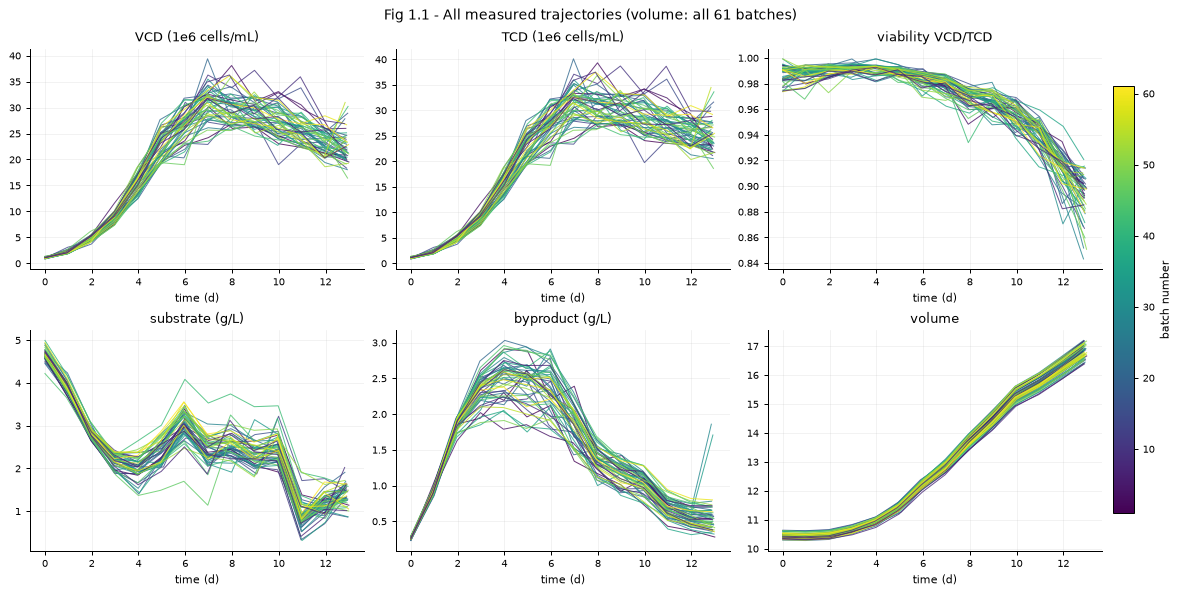

In [4]:
# Overview of all measured trajectories (train), one colour per batch.
fig, axs = plt.subplots(2, 3, figsize=(13, 6.5), constrained_layout=True)
panels = [("vcd", "VCD (1e6 cells/mL)"), ("tcd", "TCD (1e6 cells/mL)"), ("viability", "viability VCD/TCD"),
          ("substrate", "substrate (g/L)"), ("byproduct", "byproduct (g/L)"), ("volume", "volume")]
for ax, (c, lab) in zip(axs.flat, panels):
    data_ = samp if c == "volume" else meas
    for b, g in data_.groupby("batch_id"):
        ax.plot(g.elapsed_time, g[c], color=bcol(b), lw=0.8, alpha=0.8)
    ax.set_title(lab)
    ax.set_xlabel("time (d)")
batch_colorbar(fig, axs)
fig.suptitle("Fig 1.1 - All measured trajectories (volume: all 61 batches)", fontsize=11)
save(fig, "q1_overview")
plt.show()

### 1.1 Outliers
A point is flagged when it is far from the other batches at the same sample index (robust z-score on the log scale,
MAD-based) **and** inconsistent with its own neighbours in time (a spike, not a batch that is simply higher).

In [5]:
LOGV = ["vcd", "tcd", "substrate", "byproduct", "dcd"]
M = {v: meas.pivot(index="batch_id", columns="j", values=v) for v in LOGV}
rows = []
for v in LOGV:
    L = np.log(M[v].clip(lower=1e-3))
    dev = L - L.median()                       # deviation from the median trajectory
    mad = 1.4826 * (dev.sub(dev.median())).abs().median()
    z = dev / mad
    spike = dev - 0.5 * (dev.shift(1, axis=1) + dev.shift(-1, axis=1))  # departure from own neighbours
    spike_mad = 1.4826 * spike.abs().median()
    zs = spike / spike_mad
    for b in z.index:
        for j in z.columns:
            if abs(z.loc[b, j]) > 3.5 and abs(zs.loc[b, j]) > 3.5:
                rows.append(dict(var=v, batch_id=b, j=j, value=M[v].loc[b, j], z_vs_batches=z.loc[b, j],
                                 z_spike=zs.loc[b, j]))
outl = pd.DataFrame(rows)
print(f"{len(outl)} candidate outliers (|z| > 3.5 vs batches AND as a spike in time)")
display(outl.sort_values("z_spike", key=abs, ascending=False).head(20))

7 candidate outliers (|z| > 3.5 vs batches AND as a spike in time)


,var,batch_id,j,value,z_vs_batches,z_spike
3,substrate,Batch46,7,1.1396,-5.8524,-8.3808
5,dcd,Batch22,3,0.0082,-5.6907,-7.4595
0,vcd,Batch14,1,3.1003,4.2704,5.8364
1,tcd,Batch14,1,3.1265,4.1514,5.6579
4,byproduct,Batch2,1,1.1096,4.3915,5.3036
6,dcd,Batch33,4,0.0105,-7.9746,-3.9614
2,tcd,Batch47,6,19.2088,-4.3111,-3.8263


### 1.2 Measurement noise (variogram nugget)
Deviations of each batch from the mean trajectory are smooth in time if they are biological (a batch that grows
faster stays ahead), while measurement noise is independent from one sample to the next. The semi-variance of the
deviations at lag h, γ(h) = ½·E[(d_{j+h} − d_j)²], extrapolated to h = 0 (the *nugget*) estimates the noise
variance. Computed on log values, so √nugget is a relative noise (CV).

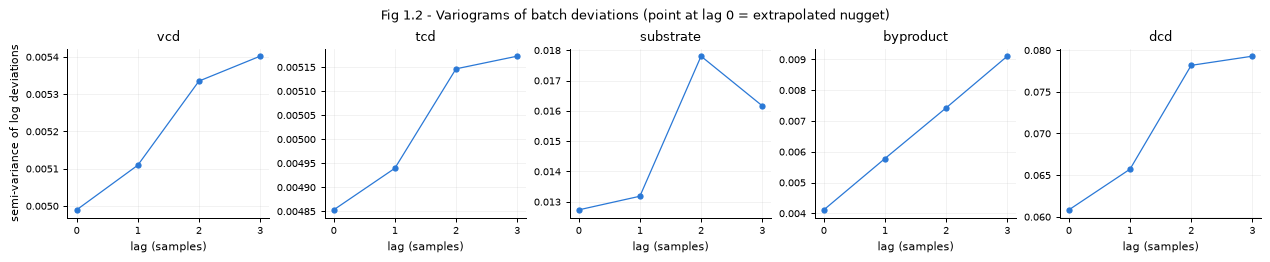

,gamma1,gamma2,gamma3,nugget,noise_cv_pct,upper_bound_cv_pct
vcd,0.0051,0.0053,0.0054,0.0050,7.0636,7.1479
tcd,0.0049,0.0051,0.0052,0.0049,6.9663,7.0281
substrate,0.0132,0.0178,0.0162,0.0127,11.2839,11.4814
byproduct,0.0058,0.0074,0.0091,0.0041,6.4123,7.6024
dcd,0.0657,0.0782,0.0793,0.0608,24.6643,25.6357


In [6]:
noise = {}
fig, axs = plt.subplots(1, 5, figsize=(14, 2.8), constrained_layout=True)
for ax, v in zip(axs, LOGV):
    L = np.log(M[v].clip(lower=1e-3))
    J = [c for c in L.columns if (v != "dcd") or c >= 1]
    dev = (L - L.mean())[J]
    gam = [0.5 * np.nanmean((dev.shift(-h, axis=1) - dev).to_numpy() ** 2) for h in (1, 2, 3)]
    a, b0 = np.polyfit([1, 2, 3], gam, 1)
    nug = max(b0, 0)
    noise[v] = dict(gamma1=gam[0], gamma2=gam[1], gamma3=gam[2], nugget=nug, noise_cv_pct=100 * np.sqrt(nug),
                    upper_bound_cv_pct=100 * np.sqrt(gam[0]))
    ax.plot([0, 1, 2, 3], [nug] + gam, "o-", color=C_TRAIN, ms=4)
    ax.set_title(v)
    ax.set_xlabel("lag (samples)")
axs[0].set_ylabel("semi-variance of log deviations")
fig.suptitle("Fig 1.2 - Variograms of batch deviations (point at lag 0 = extrapolated nugget)", fontsize=10)
save(fig, "q1_noise_variogram")
plt.show()
noise = pd.DataFrame(noise).T
display(noise.round(4))

In [7]:
# Second-difference estimate per sample index: e_j = d_j - (d_{j-1} + d_{j+1})/2 removes any smooth batch effect;
# for white noise Var(e) = 1.5 sigma^2.
nz = {}
for v in LOGV + ["viability"]:
    Lw = np.log(meas.pivot(index="batch_id", columns="j", values=v))
    dev = Lw - Lw.mean()
    e = dev - 0.5 * (dev.shift(1, axis=1) + dev.shift(-1, axis=1))
    nz[v] = 100 * np.sqrt((e ** 2).mean() / 1.5)
display(pd.DataFrame(nz).T[list(range(1, 13))].round(1))

j,1,2,3,4,5,6,7,8,9,10,11,12
vcd,9.1,7.2,6.3,6.4,5.4,7.2,7.4,6.5,6.1,6.3,5.6,7.5
tcd,9.1,7.3,6.2,6.4,5.3,7.1,7.4,6.3,5.9,6.1,5.6,6.9
substrate,1.8,2.3,3.4,6.6,5.4,5.6,9.2,9.8,8.3,10.8,23.4,17.8
byproduct,4.1,3.1,3.6,4.7,6.0,7.9,8.5,6.6,6.2,5.6,4.9,10.6
dcd,39.3,28.7,39.1,44.7,25.7,24.1,18.4,15.0,15.6,16.5,13.5,10.7
viability,0.4,0.3,0.3,0.3,0.3,0.4,0.4,0.6,0.6,0.7,0.8,1.2


**Findings (1).** The file is clean: 61 batches × 14 samples, missingness purely structural, TCD ≥ VCD everywhere,
all values > 0, viability 0.84-1.00, no duplicates. Sampling is daily (interval 0.97-1.00 d, jitter ≈ 0.6 h).
Only 7 points look like spikes; none is physically impossible (Batch46 S at j7 is a real low value that triggered a
substrate bolus; the tiny DCD of Batch22/33 are count quantisation) → keep them, use robust losses.
**Measurement noise** (white, multiplicative): VCD and TCD ≈ 6.5-7 % (the same count: VCD/TCD deviations correlate
at 0.999), DCD ≈ 25 %, substrate ≈ 2 % early (larger later because of bolus dynamics), byproduct ≈ 3-4 % early.
About half of the cross-batch VCD variance on a given day (sd ≈ 10.6 %) is this noise → **MAPE floor ≈ 5 %**
(0.8 σ) on VCD/TCD even for a perfect model.

## 2. Feeds: timing, amounts, dosing laws, likely nature

*Mechanisms tested:* (i) **bolus feeding strategies** - fixed schedule vs. feeding proportional to the cell
density (cell-specific feed rate, CSFR) vs. feedback on a measured concentration; (ii) the likely nature of each
feed (nutrient feed, concentrated glucose, pH base, antifoam, supplement) from its size, timing and response.

In [8]:
def last_sample_before(b, t):
    g = samp[(samp.batch_id == b) & (samp.elapsed_time <= t)]
    return g.iloc[-1]


rows = []
for _, r in feeds.iterrows():
    s = last_sample_before(r.batch_id, r.elapsed_time)
    rows.append(dict(batch_id=r.batch_id, feed=r.feed, t=r.elapsed_time, amount=r.amount, j=int(s.j),
                     lag_h=24 * (r.elapsed_time - s.elapsed_time), vcd=s.vcd, S=s.substrate, P=s.byproduct,
                     V=s.volume, split=s.split))
FE = pd.DataFrame(rows)
FE["hour"] = 24 * (FE.t % 1)
FE["dose_over_V"] = FE.amount / FE.V

per_batch = FE.groupby(["feed", "batch_id"]).agg(n=("amount", "size"), total=("amount", "sum"))
summ = pd.DataFrame({
    "events/batch (min-median-max)": per_batch.n.groupby("feed").apply(
        lambda s: f"{s.min()}-{int(s.median())}-{s.max()}"),
    "batches with feed": per_batch.n.groupby("feed").size(),
    "dose median": FE.groupby("feed").amount.median(),
    "dose CV %": 100 * FE.groupby("feed").amount.std() / FE.groupby("feed").amount.mean(),
    "total/batch mean": per_batch.total.groupby("feed").mean(),
    "total as % of V0": 100 * per_batch.total.groupby("feed").mean() / samp[samp.j == 0].volume.mean(),
    "first day (median)": FE.groupby(["feed", "batch_id"]).t.min().groupby("feed").median(),
    "delay after sample (h, median)": FE.groupby("feed").lag_h.median(),
})
display(summ.round(4))

,events/batch (min-median-max),batches with feed,dose median,dose CV %,total/batch mean,total as % of V0,first day (median),"delay after sample (h, median)"
feed,,,,,,,,
feed_b,12-12-12,61,0.5225,49.4417,6.5758,62.9161,0.9886,1.1426
feed_c,11-14-35,61,0.0018,35.3969,0.0211,0.2015,2.8690,1.4406
feed_d,3-3-3,61,0.0163,19.6531,0.0440,0.4209,5.0458,1.9758
feed_substrate,2-2-3,61,0.0654,20.6922,0.1611,1.5418,11.4793,12.4196


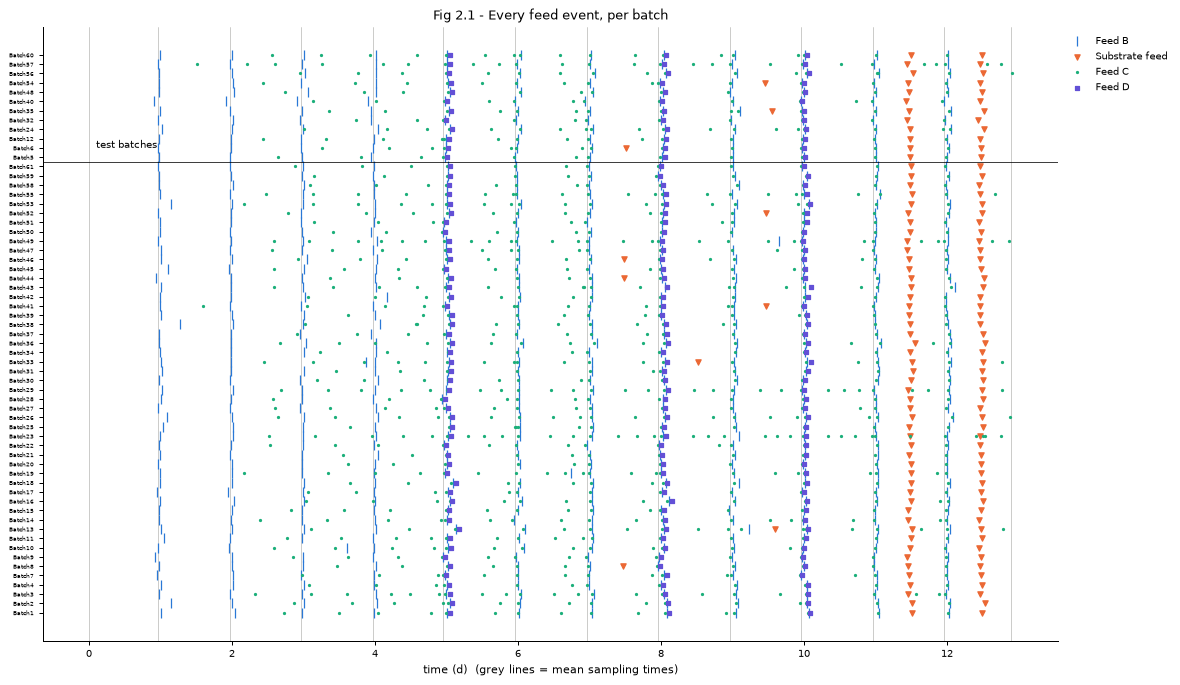

In [9]:
# Raster of every feed event (all 61 batches)
fig, ax = plt.subplots(figsize=(13, 7.5), constrained_layout=True)
order = TRAIN + TEST
ypos = {b: i for i, b in enumerate(order)}
style = {"feed_b": (C_TRAIN, "|", 60), "feed_substrate": (C_TEST, "v", 18), "feed_c": (C_3, ".", 10),
         "feed_d": (C_4, "s", 14)}
for fname, (col, mk, sz) in style.items():
    g = FE[FE.feed == fname]
    ax.scatter(g.t, g.batch_id.map(ypos), c=col, marker=mk, s=sz, label=D.FEED_LABELS[fname], lw=1)
for t in samp.groupby("j").elapsed_time.mean():
    ax.axvline(t, color=C_GREY, lw=0.4, zorder=0)
ax.axhline(len(TRAIN) - 0.5, color="k", lw=0.6)
ax.set_yticks(range(len(order)), order, fontsize=5)
ax.set_xlabel("time (d)  (grey lines = mean sampling times)")
ax.text(0.1, len(TRAIN) + 1, "test batches", fontsize=8)
ax.legend(loc="upper left", bbox_to_anchor=(1.0, 1.0))
ax.set_title("Fig 2.1 - Every feed event, per batch")
ax.grid(False)
save(fig, "q2_feed_raster")
plt.show()

### 2.1 Feed B: a pre-programmed daily schedule, not a VCD feedback
Across the whole run the Feed B dose correlates with the last measured VCD (both rise then fall), which suggests
a cell-specific feed rate (dose ∝ VCD × V). The decisive test is **within a given day**: if the dose were computed
from the measured VCD, batches with a higher VCD on that day would receive a proportionally larger dose
(elasticity 1).

pooled corr(dose, VCD_last)        = 0.87


j,1,2,3,4,5,6,7,8,9,10,11,12
dose_mean,0.0586,0.1382,0.2858,0.5123,0.8017,0.6875,0.8926,0.7891,0.8926,0.4777,0.5037,0.5166
dose_cv,0.1271,0.0809,0.0599,0.0550,0.0426,0.0477,0.0358,0.0392,0.0396,0.0360,0.0374,0.0358
csfr_mean,0.0026,0.0028,0.0030,0.0030,0.0031,0.0021,0.0023,0.0020,0.0021,0.0012,0.0013,0.0014
csfr_cv,0.1468,0.1249,0.0829,0.0955,0.0974,0.1097,0.1084,0.0961,0.0859,0.1099,0.0993,0.1006


within-day elasticities (log dose ~ log VCD + log V): {'const': 0.0, 'dlog_vcd': 0.117, 'dlog_V': 1.427} R2 = 0.122
within-day corr(dose deviation, VCD deviation) = 0.253
corr of dose deviations between days j and j+h: {1: np.float64(0.58), 2: np.float64(0.59), 4: np.float64(0.51), 8: np.float64(0.16)}


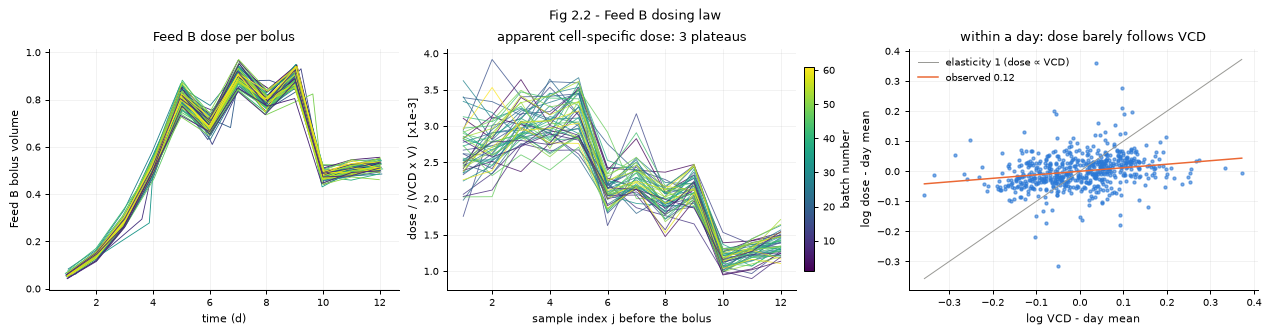

In [10]:
B = FE[FE.feed == "feed_b"].copy()
B["csfr"] = B.amount / (B.vcd * B.V)          # dose per (1e6 cells/mL x volume)
Btr = B[B.split == "train"].copy()
print("pooled corr(dose, VCD_last)        =", round(np.corrcoef(Btr.amount, Btr.vcd)[0, 1], 3))
display(Btr.groupby("j").agg(dose_mean=("amount", "mean"), dose_cv=("amount", lambda s: s.std() / s.mean()),
                             csfr_mean=("csfr", "mean"), csfr_cv=("csfr", lambda s: s.std() / s.mean())).T.round(4))

# within-day elasticity of the dose to the measured VCD and to the volume
Btr["dlog_dose"] = np.log(Btr.amount) - Btr.groupby("j").amount.transform(lambda s: np.log(s).mean())
Btr["dlog_vcd"] = np.log(Btr.vcd) - Btr.groupby("j").vcd.transform(lambda s: np.log(s).mean())
Btr["dlog_V"] = np.log(Btr.V) - Btr.groupby("j").V.transform(lambda s: np.log(s).mean())
fit = sm.OLS(Btr.dlog_dose, sm.add_constant(Btr[["dlog_vcd", "dlog_V"]])).fit()
print("within-day elasticities (log dose ~ log VCD + log V):", fit.params.round(3).to_dict(),
      "R2 =", round(fit.rsquared, 3))
print("within-day corr(dose deviation, VCD deviation) =", round(Btr[["dlog_dose", "dlog_vcd"]].corr().iloc[0, 1], 3))

# persistence of each batch's dose deviation from one day to the next (all 61 batches)
Ld = np.log(B.pivot(index="batch_id", columns="j", values="amount"))
dd = Ld - Ld.mean()
lagcorr = {h: np.nanmean([dd[j].corr(dd[j + h]) for j in range(1, 13 - h)]) for h in (1, 2, 4, 8)}
print("corr of dose deviations between days j and j+h:", {h: round(v, 2) for h, v in lagcorr.items()})

fig, axs = plt.subplots(1, 3, figsize=(14, 3.6), constrained_layout=True)
for b, g in B.groupby("batch_id"):
    axs[0].plot(g.t, g.amount, "-", color=bcol(b), lw=0.7)
    axs[1].plot(g.j, g.csfr * 1e3, "-", color=bcol(b), lw=0.7, alpha=0.8)
axs[0].set(xlabel="time (d)", ylabel="Feed B bolus volume", title="Feed B dose per bolus")
axs[1].set(xlabel="sample index j before the bolus", ylabel="dose / (VCD x V)  [x1e-3]",
           title="apparent cell-specific dose: 3 plateaus")
axs[2].scatter(Btr.dlog_vcd, Btr.dlog_dose, s=6, color=C_TRAIN, alpha=0.6)
xx = np.linspace(Btr.dlog_vcd.min(), Btr.dlog_vcd.max(), 10)
axs[2].plot(xx, xx, color=C_GREY, lw=0.8, label="elasticity 1 (dose ∝ VCD)")
axs[2].plot(xx, fit.params["dlog_vcd"] * xx, color=C_TEST, lw=1.2, label=f"observed {fit.params['dlog_vcd']:.2f}")
axs[2].set(xlabel="log VCD - day mean", ylabel="log dose - day mean", title="within a day: dose barely follows VCD")
axs[2].legend()
batch_colorbar(fig, axs[:2])
fig.suptitle("Fig 2.2 - Feed B dosing law", fontsize=10)
save(fig, "q2_feedB_law")
plt.show()

### 2.2 Substrate feed, Feed C, Feed D

dose/V values (rounded): {0.004: 85, 0.006: 47}


n  S_before_min  S_before_max  delay_h
j  level                                           
7  0.004 V   4        1.1396        1.8700  12.4803
8  0.004 V   1        1.9122        1.9122  12.7169
9  0.004 V   5        1.8009        1.8687  12.4147
11 0.004 V  24        0.9694        1.9302  12.3892
   0.006 V  37        0.3140        0.9518  12.4867
12 0.004 V  51        0.9723        1.7805  12.3925
   0.006 V  10        0.7073        0.9639  12.4754

batches with a mid-run (j<11) substrate bolus: ['Batch6', 'Batch8', 'Batch13', 'Batch33', 'Batch35', 'Batch41', 'Batch44', 'Batch46', 'Batch52', 'Batch54']


,n,dose,dose_cv,first_day,hour_median,delay_after_sample_h
class,,,,,,
large (scheduled),488,0.0018,0.0103,4.9247,23.0701,0.7910
small (on demand),469,0.0009,0.0140,1.5069,15.8461,16.6444


,t_mean,t_sd_h,dose,dose_cv,dose_over_V,dose_over_V_cv
k,,,,,,
1,5.0443,0.8194,0.0170,0.0095,0.0015,0.0051
2,8.0509,0.7725,0.0163,0.0137,0.0012,0.0082
3,10.0269,0.6999,0.0106,0.0122,0.0007,0.0068


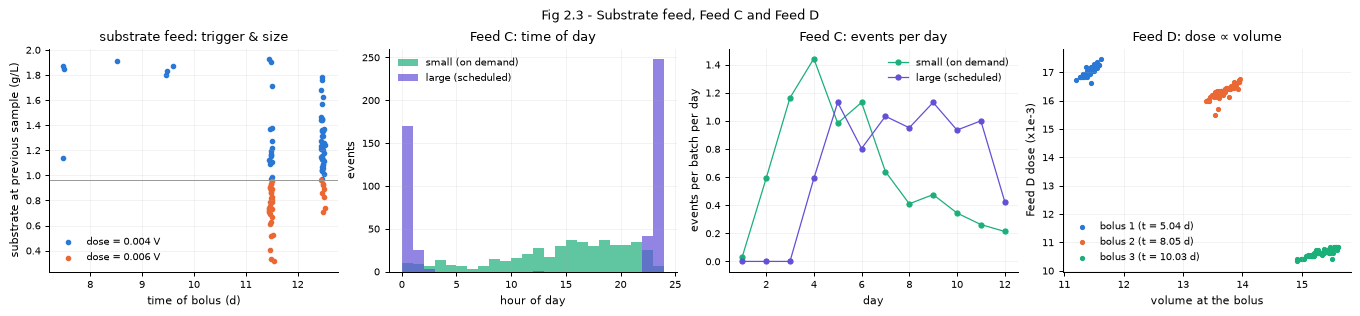

In [11]:
Fs = FE[FE.feed == "feed_substrate"].copy()
Fs["level"] = np.where(Fs.dose_over_V > 0.005, "0.006 V", "0.004 V")
print("dose/V values (rounded):", Fs.dose_over_V.round(4).value_counts().to_dict())
display(Fs.groupby(["j", "level"]).agg(n=("amount", "size"), S_before_min=("S", "min"), S_before_max=("S", "max"),
                                       delay_h=("lag_h", "median")))
mid = Fs[Fs.j < 11].batch_id.unique()
print("batches with a mid-run (j<11) substrate bolus:", list(mid))

C = FE[FE.feed == "feed_c"].copy()
C["class"] = np.where(C.amount > 0.0013, "large (scheduled)", "small (on demand)")
display(C.groupby("class").agg(n=("amount", "size"), dose=("amount", "median"), dose_cv=("amount", lambda s: s.std() / s.mean()),
                               first_day=("t", "min"), hour_median=("hour", "median"),
                               delay_after_sample_h=("lag_h", "median")))
Dd = FE[FE.feed == "feed_d"].copy()
Dd["k"] = Dd.groupby("batch_id").cumcount() + 1
display(Dd.groupby("k").agg(t_mean=("t", "mean"), t_sd_h=("t", lambda s: 24 * s.std()), dose=("amount", "mean"),
                            dose_cv=("amount", lambda s: s.std() / s.mean()), dose_over_V=("dose_over_V", "mean"),
                            dose_over_V_cv=("dose_over_V", lambda s: s.std() / s.mean())))

fig, axs = plt.subplots(1, 4, figsize=(15, 3.4), constrained_layout=True)
ax = axs[0]
for lev, col in [("0.004 V", C_TRAIN), ("0.006 V", C_TEST)]:
    g = Fs[(Fs.level == lev) & (Fs.split == "train")]
    ax.scatter(g.t, g.S, s=12, color=col, label=f"dose = {lev}")
ax.axhline(0.96, color=C_GREY, lw=0.8)
ax.set(xlabel="time of bolus (d)", ylabel="substrate at previous sample (g/L)", title="substrate feed: trigger & size")
ax.legend()
ax = axs[1]
bins = np.arange(0, 24.5, 1)
for cl, col in [("small (on demand)", C_3), ("large (scheduled)", C_4)]:
    ax.hist(C[C["class"] == cl].hour, bins=bins, color=col, alpha=0.7, label=cl)
ax.set(xlabel="hour of day", ylabel="events", title="Feed C: time of day")
ax.legend()
ax = axs[2]
cnt = C.assign(day=np.floor(C.t)).groupby(["day", "class"]).size().unstack(fill_value=0) / raw.batch_id.nunique()
for cl, col in [("small (on demand)", C_3), ("large (scheduled)", C_4)]:
    ax.plot(cnt.index, cnt[cl], "o-", color=col, ms=4, label=cl)
ax.set(xlabel="day", ylabel="events per batch per day", title="Feed C: events per day")
ax.legend()
ax = axs[3]
for k, col in zip([1, 2, 3], [C_TRAIN, C_TEST, C_3]):
    g = Dd[Dd.k == k]
    ax.scatter(g.V, g.amount * 1e3, s=10, color=col, label=f"bolus {k} (t = {g.t.mean():.2f} d)")
ax.set(xlabel="volume at the bolus", ylabel="Feed D dose (x1e-3)", title="Feed D: dose ∝ volume")
ax.legend()
fig.suptitle("Fig 2.3 - Substrate feed, Feed C and Feed D", fontsize=10)
save(fig, "q2_feeds_S_C_D")
plt.show()

In [12]:
# Feed C on-demand events: when do they happen relative to the biology? (train intervals)
def interval_window(b, t0, t1):
    return FE[(FE.batch_id == b) & (FE.t > t0) & (FE.t <= t1)]


rows = []
for b in TRAIN:
    g = meas[meas.batch_id == b].reset_index(drop=True)
    for i in range(1, len(g)):
        w = interval_window(b, g.elapsed_time[i - 1], g.elapsed_time[i])
        c = w[w.feed == "feed_c"]
        dti = g.elapsed_time[i] - g.elapsed_time[i - 1]
        rows.append(dict(batch_id=b, j=i, n_small=(c.amount < 0.0013).sum(), n_large=(c.amount >= 0.0013).sum(),
                         dX=(g.vcd[i] - g.vcd[i - 1]) / dti, dP=(g.byproduct[i] - g.byproduct[i - 1]) / dti,
                         Xbar=0.5 * (g.vcd[i] + g.vcd[i - 1]), P=g.byproduct[i - 1]))
CI_ = pd.DataFrame(rows)
display(CI_.groupby("j")[["n_small", "n_large", "dX", "dP", "Xbar"]].mean().T.round(2))
Z = CI_.groupby("j")[["n_small", "dX", "dP", "Xbar", "P"]].transform(lambda s: s - s.mean())
print("within-interval correlations of the number of small Feed C events with the biology:")
display(Z.corr().loc[["n_small"]].round(2))
tot_small = CI_.groupby("batch_id").n_small.sum()
print("small Feed C events per batch: min", tot_small.min(), "median", tot_small.median(), "max", tot_small.max())

j,1,2,3,4,5,6,7,8,9,10,11,12,13
n_small,0.00,0.02,0.55,1.18,1.49,1.00,1.14,0.67,0.41,0.49,0.39,0.24,0.20
n_large,0.00,0.00,0.00,0.00,0.00,1.00,1.00,1.00,1.00,0.98,1.00,1.00,1.02
dX,1.11,2.67,4.09,6.67,7.06,4.12,3.98,-0.82,-0.84,-1.68,-1.46,-2.47,-0.96
dP,0.69,0.93,0.47,0.16,-0.06,-0.09,-0.46,-0.51,-0.19,-0.15,-0.34,-0.12,0.01
Xbar,1.61,3.49,6.88,12.27,19.09,24.63,28.67,30.25,29.41,28.15,26.59,24.63,22.93


within-interval correlations of the number of small Feed C events with the biology:


,n_small,dX,dP,Xbar,P
n_small,1.0,0.01,0.0,-0.28,-0.19


small Feed C events per batch: min 3 median 7.0 max 27


**Findings (2).**
* **Feed B** (12 boluses ≈ 1 h after each sample, day 1 → 12, total 6.6 = 63 % of V₀) is a **pre-programmed
  schedule**: its shape follows the expected VCD curve (apparent cell-specific dose with 3 plateaus ≈ 3.0·10⁻³,
  2.1·10⁻³, 1.3·10⁻³ per (10⁶ cells/mL·V) on days 1-5, 6-9, 10-12), but within a day the dose barely follows the
  measured VCD (elasticity 0.12, R² 0.12). Each batch has a smooth multiplier (±4 %, day-to-day corr 0.58) only
  weakly tied to its VCD level. → mostly exogenous; the "dose ∝ last VCD (r = 0.87)" in CLAUDE.md is a time artefact.
  Mass balance (section 3): ≈ 53 g/L substrate, no byproduct → concentrated **nutrient feed**.
* **Substrate feed**: dose exactly 0.004·V or 0.006·V (raises S by ≈ +1.0 / +1.5 g/L), ≈ 12.4 h after sampling;
  2 late boluses in every batch (j11, j12; 0.006·V when S < ≈ 0.96 g/L) and a mid-run 0.004·V bolus in 10/61
  batches when S < ≈ 1.9 g/L → **feedback controller on measured S** (its actions reveal S in test batches).
* **Feed C**: two populations of the same liquid: 0.0018 once a day from day 5 at sampling time (scheduled, no
  information) and 0.00086 shots on demand at any hour (3-27 per batch, mostly days 3-7). Negligible volume
  (0.2 % of V₀). On-demand shots are more frequent in batches with fewer cells and less final byproduct and do not
  follow lactate production → not base. Most likely pH/foam control additive (antifoam or acid); low confidence.
* **Feed D**: 3 boluses at 5.04 / 8.05 / 10.03 d in all 61 batches, dose = 0.149 / 0.119 / 0.069 % of V (CV < 1 %)
  → fixed recipe supplement (no state information, no detectable substrate).

## 3. Volume & mass balances

*Mechanism tested:* **conservation of volume and mass** in a fed-batch reactor. With bolus feeds of volume ΔV_f at
concentration C_f: V⁺ = V + ΔV_f and C⁺ = (C·V + C_f·ΔV_f)/V⁺. Sampling removes volume without changing
concentrations; base for pH control adds unrecorded volume. Working on **amounts** (C × V) separates true biology
from pure dilution.

In [13]:
# 3.1 Volume reconstruction and budget
H = []  # unexplained ("hidden") volume per interval = measured dV - recorded feeds
for b, g in samp.groupby("batch_id"):
    g = g.sort_values("elapsed_time").reset_index(drop=True)
    for i in range(1, len(g)):
        w = interval_window(b, g.elapsed_time[i - 1], g.elapsed_time[i])
        fed = w.amount.sum()
        H.append(dict(batch_id=b, j=i, dt=g.elapsed_time[i] - g.elapsed_time[i - 1], dV=g.volume[i] - g.volume[i - 1],
                      fed=fed, hidden=g.volume[i] - g.volume[i - 1] - fed, split=g.split[i]))
H = pd.DataFrame(H)
print("corr(dV, recorded feeds) over all intervals:", round(np.corrcoef(H.dV, H.fed)[0, 1], 4))
display(H.pivot_table(index="split", columns="j", values="hidden", aggfunc="mean").round(4))

# Late intervals (j >= 6): no base needed any more -> hidden = -(sampling + evaporation). Regress on interval length.
late = H[(H.j >= 6)]
slope, icpt = np.polyfit(late.dt, late.hidden, 1)
W_PER_INTERVAL = -late.hidden.median()
print(f"late intervals: hidden = {icpt:.4f} + {slope:.4f} * dt   -> withdrawal ~ {W_PER_INTERVAL:.4f} per interval")
H["base_est"] = H.hidden + W_PER_INTERVAL   # base (or other unrecorded additions) = hidden + withdrawal

budget = pd.DataFrame({
    "V0": samp[samp.j == 0].set_index("batch_id").volume,
    **{D.FEED_LABELS[f]: FE[FE.feed == f].groupby("batch_id").amount.sum() for f in D.FEEDS},
    "hidden (sum)": H.groupby("batch_id").hidden.sum(),
    "V_end": samp[samp.j == 13].set_index("batch_id").volume,
}).fillna(0)
budget["check: V0+feeds+hidden-V_end"] = budget.drop(columns="V_end").sum(axis=1) - budget.V_end
display(budget.describe().loc[["mean", "std", "min", "max"]].round(4))

corr(dV, recorded feeds) over all intervals: 0.9974


j,1,2,3,4,5,6,7,8,9,10,11,12,13
split,,,,,,,,,,,,,
test,-0.0203,-0.0137,0.0384,-0.0020,-0.0258,-0.0517,-0.0546,-0.0552,-0.0525,-0.0496,-0.0519,-0.0482,-0.0538
train,-0.0187,-0.0168,0.0409,-0.0038,-0.0276,-0.0465,-0.0519,-0.0592,-0.0497,-0.0510,-0.0499,-0.0465,-0.0520


late intervals: hidden = -0.0201 + -0.0312 * dt   -> withdrawal ~ 0.0513 per interval


,V0,Substrate feed,Feed B,Feed C,Feed D,hidden (sum),V_end,check: V0+feeds+hidden-V_end
mean,10.4518,0.1611,6.5758,0.0211,0.0440,-0.4343,16.8195,0.0
std,0.0775,0.0197,0.2083,0.0042,0.0004,0.0252,0.2152,0.0
min,10.2982,0.1252,6.1805,0.0170,0.0430,-0.4885,16.3856,-0.0
max,10.6384,0.2098,6.9605,0.0375,0.0450,-0.3835,17.1964,0.0


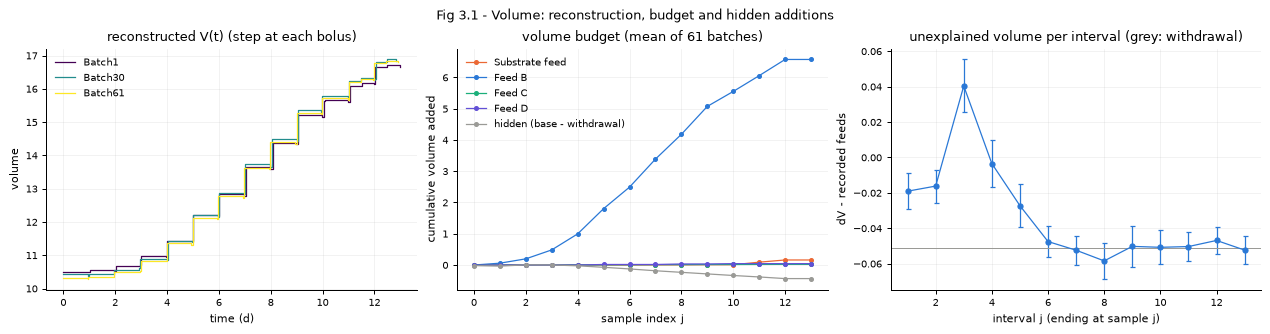

In [14]:
fig, axs = plt.subplots(1, 3, figsize=(14, 3.6), constrained_layout=True)
ax = axs[0]
for b in ["Batch1", "Batch30", "Batch61"]:
    vp = D.volume_profile(raw, b)
    ax.step(vp.elapsed_time, vp.volume, where="post", color=bcol(b), label=b)
ax.set(xlabel="time (d)", ylabel="volume", title="reconstructed V(t) (step at each bolus)")
ax.legend()
ax = axs[1]
cum = {}
for f in D.FEEDS:
    x = FE[FE.feed == f].groupby(["batch_id", "j"]).amount.sum().unstack(fill_value=0)
    x = x.reindex(columns=range(14), fill_value=0).reindex(raw.batch_id.unique(), fill_value=0).cumsum(axis=1)
    cum[D.FEED_LABELS[f]] = x.mean()
cum = pd.DataFrame(cum)
cum["hidden (base - withdrawal)"] = H.pivot(index="batch_id", columns="j", values="hidden").cumsum(axis=1).mean() \
    .reindex(range(14)).shift(-1).ffill()
for (c, col) in zip(cum.columns, [C_TEST, C_TRAIN, C_3, C_4, C_GREY]):
    ax.plot(cum.index, cum[c], "o-", ms=3, color=col, label=c)
ax.set(xlabel="sample index j", ylabel="cumulative volume added", title="volume budget (mean of 61 batches)")
ax.legend()
ax = axs[2]
hm = H.groupby("j").hidden.agg(["mean", "std"])
ax.errorbar(hm.index, hm["mean"], yerr=hm["std"], fmt="o-", color=C_TRAIN, ms=4, capsize=2)
ax.axhline(-W_PER_INTERVAL, color=C_GREY, lw=0.8)
ax.set(xlabel="interval j (ending at sample j)", ylabel="dV - recorded feeds",
       title="unexplained volume per interval (grey: withdrawal)")
fig.suptitle("Fig 3.1 - Volume: reconstruction, budget and hidden additions", fontsize=10)
save(fig, "q3_volume_budget")
plt.show()

### 3.2 Interval mass balances (train batches)
For every interval between two samples we compute, from measured values only:
* amounts N = VCD·V (viable cells), Dd = DCD·V (dead cells), S·V, P·V;
* IVC = ∫ N dt over the interval (log-mean of the two end amounts, exact for exponential growth);
* withdrawal w (sampling + evaporation) from the late-interval fit above, removed at the mean concentration.

Biology per interval (no lysis assumed):
μ_net = ln[(N₁ + X̄·w)/N₀]/Δt, k_d = (ΔDd + D̄·w)/IVC, μ = μ_net + k_d,
substrate consumed = S₀V₀ + C_B·B + C_F·F − S₁V₁ − S̄·w, byproduct produced = P₁V₁ − P₀V₀ + P̄·w.
The feed concentrations C_B (substrate in Feed B) and C_F (substrate feed) are unknown: they are estimated
by least squares on the substrate balance, with a free specific consumption rate per interval.

,C_B,C_B_lo,C_B_hi,C_F,n_params,resid_sd,AIC
free q per interval (13 q),7.310,3.757,10.863,288.986,15.0,2.382,2928.174
"q = polynomial(t), degree 2",51.766,48.134,55.399,315.832,5.0,4.727,3791.601
"q = polynomial(t), degree 3",47.759,44.211,51.308,280.461,6.0,4.467,3720.654
"q = polynomial(t), degree 4",50.454,47.197,53.711,274.437,7.0,4.059,3599.632
Pirt: q = mu/Y + m,54.631,51.553,57.710,245.234,4.0,5.145,3898.654
Pirt + overflow: q = mu/Y + m + b*qP+,52.860,50.477,55.242,249.674,5.0,3.972,3569.986


Pirt + overflow parameters: {'C_B': 52.86, 'C_F': 249.674, '1/Y': -0.004, 'm': 0.109, 'b': 0.858}
retained: C_B = 52.9, C_F = 249.7  (C_F / C_B = 4.7)
substrate concentration in C_D (Feed D): 35 (95% CI -20 .. 91)
substrate concentration in C_C (Feed C): -2429 (95% CI -2899 .. -1960)


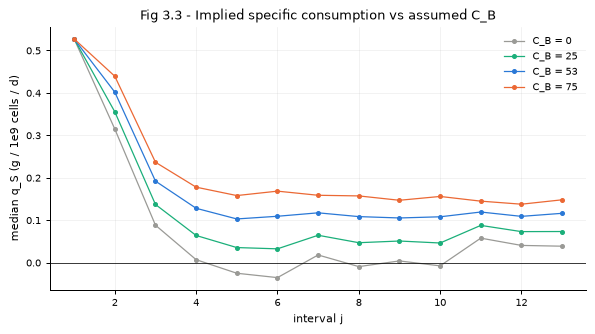

byproduct concentration in Feed B (should be ~0): 0.86 (95% CI -2.24 - 3.96)


j,1,2,3,4,5,6,7,8,9,10,11,12,13
tm,0.483,1.467,2.468,3.469,4.465,5.457,6.460,7.459,8.460,9.463,10.456,11.458,12.427
mu_net,0.702,0.829,0.627,0.597,0.421,0.233,0.173,0.038,0.034,0.011,-0.030,-0.048,-0.041
kd,0.008,0.006,0.004,0.004,0.006,0.008,0.008,0.011,0.005,0.012,0.013,0.026,0.023
mu,0.715,0.835,0.625,0.603,0.430,0.240,0.189,0.050,0.043,0.027,-0.010,-0.019,-0.017
qS,0.527,0.402,0.192,0.128,0.103,0.109,0.117,0.108,0.105,0.108,0.119,0.109,0.116
qP,0.449,0.294,0.079,0.020,0.003,0.004,-0.012,-0.014,-0.004,-0.003,-0.012,-0.004,-0.001


In [15]:
def logmean(a, b):
    a, b = np.asarray(a, float), np.asarray(b, float)
    with np.errstate(divide="ignore", invalid="ignore"):
        lm = (b - a) / np.log(b / a)
    return np.where(np.isclose(a, b), 0.5 * (a + b), lm)


rows = []
for b in TRAIN:
    g = meas[meas.batch_id == b].sort_values("elapsed_time").reset_index(drop=True)
    for i in range(1, len(g)):
        a, c = g.iloc[i - 1], g.iloc[i]
        w = interval_window(b, a.elapsed_time, c.elapsed_time)
        tot = w.groupby("feed").amount.sum()
        dti = c.elapsed_time - a.elapsed_time
        rows.append(dict(
            batch_id=b, j=i, t0=a.elapsed_time, t1=c.elapsed_time, dt=dti, tm=0.5 * (a.elapsed_time + c.elapsed_time),
            V0=a.volume, V1=c.volume, X0=a.vcd, X1=c.vcd, T0=a.tcd, T1=c.tcd, D0=a.dcd, D1=c.dcd,
            S0=a.substrate, S1=c.substrate, P0=a.byproduct, P1=c.byproduct,
            B=tot.get("feed_b", 0.0), F=tot.get("feed_substrate", 0.0), Cv=tot.get("feed_c", 0.0),
            Dv=tot.get("feed_d", 0.0), wd=-(icpt + slope * dti)))
I = pd.DataFrame(rows)
I["N0"], I["N1"] = I.X0 * I.V0, I.X1 * I.V1
I["IVC"] = logmean(I.N0, I.N1) * I.dt                      # integral of viable cell amount (cells x volume x d)
I["IVCD"] = logmean(I.X0, I.X1) * I.dt                     # integral of viable cell concentration
I["mu_net"] = np.log((I.N1 + 0.5 * (I.X0 + I.X1) * I.wd) / I.N0) / I.dt
I["kd"] = (I.D1 * I.V1 - I.D0 * I.V0 + 0.5 * (I.D0 + I.D1) * I.wd) / I.IVC
I["mu"] = I.mu_net + I.kd
I["dT_amt"] = I.T1 * I.V1 - I.T0 * I.V0 + 0.5 * (I.T0 + I.T1) * I.wd   # change of total cell amount
I["P_prod"] = I.P1 * I.V1 - I.P0 * I.V0 + 0.5 * (I.P0 + I.P1) * I.wd
I["S_net"] = I.S1 * I.V1 - I.S0 * I.V0 + 0.5 * (I.S0 + I.S1) * I.wd      # = inputs - consumption

# Substrate balance regression: S_net = C_B*B + C_F*F - consumption, for several consumption structures.
# Feed B is given every day on a smooth schedule, so its concentration is confounded with the consumption profile:
# we compare structures and keep the one that is physically consistent (consumption >= 0) and parsimonious.
I["growth"] = I.mu * I.IVC                         # gross new cells formed in the interval (amount)
structures = {}


def fit_balance(name, extra):
    Xr = pd.concat([pd.DataFrame({"C_B": I.B, "C_F": I.F}), extra], axis=1)
    o = sm.OLS(I.S_net, Xr).fit()
    structures[name] = dict(C_B=o.params.C_B, C_B_lo=o.conf_int().loc["C_B", 0], C_B_hi=o.conf_int().loc["C_B", 1],
                            C_F=o.params.C_F, n_params=Xr.shape[1], resid_sd=np.sqrt(o.scale), AIC=o.aic)
    return o


fit_balance("free q per interval (13 q)", pd.DataFrame({f"q{j}": -I.IVC * (I.j == j) for j in range(1, 14)}))
for deg in (2, 3, 4):
    fit_balance(f"q = polynomial(t), degree {deg}", pd.DataFrame({f"q{k}": -I.IVC * (I.tm / 13) ** k for k in range(deg + 1)}))
fit_balance("Pirt: q = mu/Y + m", pd.DataFrame({"1/Y": -I.growth, "m": -I.IVC}))
o_pirt = fit_balance("Pirt + overflow: q = mu/Y + m + b*qP+",
                     pd.DataFrame({"1/Y": -I.growth, "m": -I.IVC, "b": -I.P_prod.clip(lower=0)}))
display(pd.DataFrame(structures).T.round(3))
print("Pirt + overflow parameters:", o_pirt.params.round(3).to_dict())
CB, CF = o_pirt.params["C_B"], o_pirt.params["C_F"]
print(f"retained: C_B = {CB:.1f}, C_F = {CF:.1f}  (C_F / C_B = {CF / CB:.1f})")

# Does Feed D or Feed C carry substrate? Add each one's volume to the retained balance (one at a time).
for col, name in [("Dv", "C_D (Feed D)"), ("Cv", "C_C (Feed C)")]:
    o_x = sm.OLS(I.S_net, pd.DataFrame({"C_B": I.B, "C_F": I.F, name: I[col], "1/Y": -I.growth, "m": -I.IVC,
                                        "b": -I.P_prod.clip(lower=0)})).fit()
    lo, hi = o_x.conf_int().loc[name]
    print(f"substrate concentration in {name}: {o_x.params[name]:.0f} (95% CI {lo:.0f} .. {hi:.0f})")

# Physical constraint: the per-interval consumption implied by a given C_B must be >= 0
fig, ax = plt.subplots(figsize=(6.5, 3.6), constrained_layout=True)
for cb, col in zip([0, 25, CB, 75], [C_GREY, C_3, C_TRAIN, C_TEST]):
    q = ((cb * I.B + CF * I.F - I.S_net) / I.IVC).groupby(I.j).median()
    ax.plot(q.index, q.values, "o-", ms=3, color=col, label=f"C_B = {cb:.0f}")
ax.axhline(0, color="k", lw=0.6)
ax.set(xlabel="interval j", ylabel="median q_S (g / 1e9 cells / d)",
       title="Fig 3.3 - Implied specific consumption vs assumed C_B")
ax.legend()
save(fig, "q3_feed_concentration")
plt.show()

# Does Feed B also carry byproduct? (byproduct balance with a free production rate per interval)
Xq = pd.DataFrame({"P_in_B": I.B})
for j in range(1, 14):
    Xq[f"q{j}"] = I.IVC * (I.j == j)
olsP = sm.OLS(I.P_prod, Xq).fit()
print(f"byproduct concentration in Feed B (should be ~0): {olsP.params['P_in_B']:.2f} "
      f"(95% CI {olsP.conf_int().loc['P_in_B', 0]:.2f} - {olsP.conf_int().loc['P_in_B', 1]:.2f})")

I["S_cons"] = CB * I.B + CF * I.F - I.S_net
I["qS"] = I.S_cons / I.IVC        # g / (1e9 cells) / d  =  ng/cell/d with the assumed units
I["qP"] = I.P_prod / I.IVC
display(I.groupby("j")[["tm", "mu_net", "kd", "mu", "qS", "qP"]].median().T.round(3))

### 3.3 Dilution vs biology
Concentration changes per interval split into: dilution of what was there (C₀·(V₀/V₁ − 1)), feed input
(C_f·ΔV_f/V₁) and the biological term (growth, consumption, production). Mean over the 49 train batches.

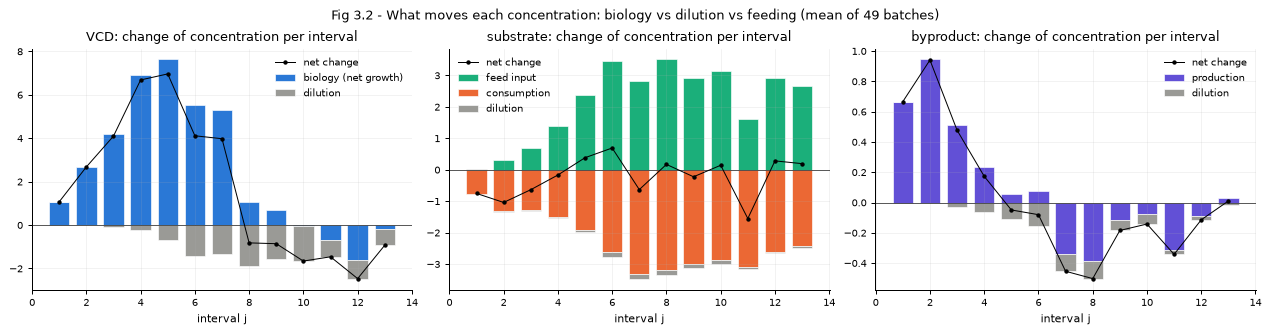

from peak to day 13: VCD concentration falls by 29% (median), viable cell AMOUNT by only 9%  -> 69% of the apparent decline is dilution


In [16]:
dec = pd.DataFrame({
    "j": I.j,
    "VCD: dilution": I.X0 * (I.V0 / I.V1 - 1),
    "VCD: biology (net growth)": (I.N1 - I.N0) / I.V1,
    "S: dilution": I.S0 * (I.V0 / I.V1 - 1),
    "S: feed input": (CB * I.B + CF * I.F) / I.V1,
    "S: consumption": -I.S_cons / I.V1,
    "P: dilution": I.P0 * (I.V0 / I.V1 - 1),
    "P: production": I.P_prod / I.V1,
}).groupby("j").mean()
fig, axs = plt.subplots(1, 3, figsize=(14, 3.6), constrained_layout=True)
specs = [("VCD", ["VCD: biology (net growth)", "VCD: dilution"], [C_TRAIN, C_GREY]),
         ("substrate", ["S: feed input", "S: consumption", "S: dilution"], [C_3, C_TEST, C_GREY]),
         ("byproduct", ["P: production", "P: dilution"], [C_4, C_GREY])]
for ax, (title, comps, cols_) in zip(axs, specs):
    pos = np.zeros(len(dec))
    neg = np.zeros(len(dec))
    for comp, col in zip(comps, cols_):
        v = dec[comp].to_numpy()
        base = np.where(v >= 0, pos, neg)
        ax.bar(dec.index, v, bottom=base, color=col, width=0.75, label=comp.split(": ")[1], edgecolor="white", lw=0.5)
        pos = np.where(v >= 0, pos + v, pos)
        neg = np.where(v < 0, neg + v, neg)
    net = dec[comps].sum(axis=1)
    ax.plot(dec.index, net, "k.-", ms=5, lw=0.8, label="net change")
    ax.axhline(0, color="k", lw=0.5)
    ax.set(title=f"{title}: change of concentration per interval", xlabel="interval j")
    ax.legend()
fig.suptitle("Fig 3.2 - What moves each concentration: biology vs dilution vs feeding (mean of 49 batches)",
             fontsize=10)
save(fig, "q3_dilution_decomposition")
plt.show()

# Post-peak VCD: concentration vs amount
pk = meas.loc[meas.groupby("batch_id").vcd.idxmax(), ["batch_id", "j"]].set_index("batch_id").j
end = meas[meas.j == 13].set_index("batch_id")
atpk = meas.set_index(["batch_id", "j"]).loc[list(zip(pk.index, pk.values))].reset_index().set_index("batch_id")
drop_conc = 1 - end.vcd / atpk.vcd
drop_amt = 1 - (end.vcd * end.volume) / (atpk.vcd * atpk.volume)
print(f"from peak to day 13: VCD concentration falls by {100 * drop_conc.median():.0f}% (median), "
      f"viable cell AMOUNT by only {100 * drop_amt.median():.0f}%  -> "
      f"{100 * (1 - drop_amt.median() / drop_conc.median()):.0f}% of the apparent decline is dilution")

**Findings (3).** ΔV = Σ feeds + hidden (corr 0.997); V grows 10.45 → 16.8 (+61 %), 96 % from Feed B. The hidden
volume is −0.051 per interval late (≈ 0.02 sampling + 0.031·Δt evaporation) and shows a **surplus of +0.03 to +0.09
in intervals 1-5 = unrecorded base for pH control** (peak in interval 3, when the medium buffer is exhausted); it
tracks the lactate made (r ≈ 0.6-0.7, ≈ 0.009 volume per g lactate ≈ 1.2 M base if V is in litres).
Feed concentrations: **C_B ≈ 53 g/L** (48-57 across plausible consumption structures; C_B < 20 would make the
consumption negative on days 4-6), **C_F ≈ 250 g/L** (C_F/C_B ≈ 4.7). The "free q per interval" estimate (7) is not
identified (Feed B is collinear with time). After the VCD peak, **69 % of the apparent VCD decline is dilution**
(concentration −29 %, viable cell amount −9 %).

## 4. Growth phases

*Mechanism tested:* **exponential growth** dN/dt = μ·N with a phase-dependent μ (lag / exponential / deceleration /
stationary / decline), as in Monod-type unstructured models (Kyriakopoulos 2018; Xing 2010) and the logistic
description of CHO fed-batch growth (Goudar 2005). Working on cell **amounts** removes the dilution by feeds.

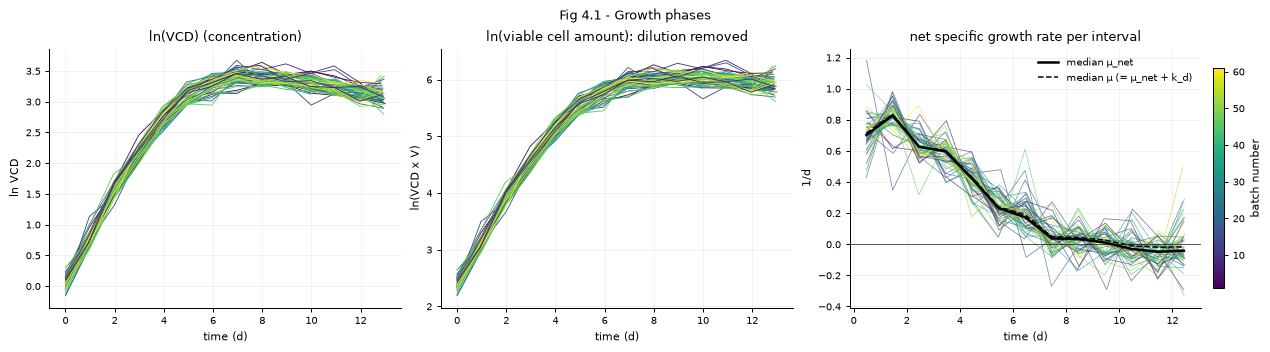

,j,1,2,3,4,5,6,7,8,9,10,11,12,13
tm,50%,0.483,1.467,2.468,3.469,4.465,5.457,6.460,7.459,8.460,9.463,10.456,11.458,12.427
mu_net,50%,0.702,0.829,0.627,0.597,0.421,0.233,0.173,0.038,0.034,0.011,-0.030,-0.048,-0.041
mu,50%,0.715,0.835,0.625,0.603,0.430,0.240,0.189,0.050,0.043,0.027,-0.010,-0.019,-0.017
tm,25%,0.475,1.458,2.454,3.460,4.453,5.445,6.451,7.445,8.447,9.447,10.447,11.450,12.411
mu_net,25%,0.660,0.776,0.584,0.538,0.372,0.186,0.112,-0.006,-0.028,-0.059,-0.087,-0.112,-0.091
mu,25%,0.670,0.782,0.590,0.540,0.384,0.194,0.121,0.002,-0.024,-0.050,-0.074,-0.092,-0.053
tm,75%,0.491,1.477,2.481,3.480,4.473,5.470,6.476,7.482,8.477,9.477,10.477,11.476,12.448
mu_net,75%,0.758,0.874,0.676,0.646,0.477,0.294,0.252,0.088,0.077,0.065,0.011,-0.007,0.046
mu,75%,0.774,0.880,0.681,0.651,0.487,0.306,0.263,0.099,0.079,0.081,0.028,0.024,0.060


In [17]:
meas["N"] = meas.vcd * meas.volume
fig, axs = plt.subplots(1, 3, figsize=(14, 3.8), constrained_layout=True)
for b, g in meas.groupby("batch_id"):
    axs[0].plot(g.elapsed_time, np.log(g.vcd), color=bcol(b), lw=0.7)
    axs[1].plot(g.elapsed_time, np.log(g.N), color=bcol(b), lw=0.7)
    gi = I[I.batch_id == b]
    axs[2].plot(gi.tm, gi.mu_net, color=bcol(b), lw=0.6, alpha=0.7)
med = I.groupby("j")[["tm", "mu_net", "mu"]].median()
axs[2].plot(med.tm, med.mu_net, "k-", lw=2, label="median μ_net")
axs[2].plot(med.tm, med.mu, "--", color="k", lw=1.2, label="median μ (= μ_net + k_d)")
axs[2].axhline(0, color="k", lw=0.5)
axs[0].set(xlabel="time (d)", ylabel="ln VCD", title="ln(VCD) (concentration)")
axs[1].set(xlabel="time (d)", ylabel="ln(VCD x V)", title="ln(viable cell amount): dilution removed")
axs[2].set(xlabel="time (d)", ylabel="1/d", title="net specific growth rate per interval")
axs[2].legend()
batch_colorbar(fig, axs)
fig.suptitle("Fig 4.1 - Growth phases", fontsize=10)
save(fig, "q4_growth_phases")
plt.show()
display(I.groupby("j")[["tm", "mu_net", "mu"]].describe().loc[:, (slice(None), ["50%", "25%", "75%"])].round(3).T)

In [18]:
# Per-batch phase parameters
def batch_growth(b):
    g = meas[meas.batch_id == b].sort_values("elapsed_time")
    gi = I[I.batch_id == b].sort_values("j")
    t, lnN = g.elapsed_time.to_numpy(), np.log(g.N.to_numpy())
    res = {}
    # exponential phase: slope of ln N over samples 0..3 (r2 checks the straightness)
    sl = stats.linregress(t[:4], lnN[:4])
    res["mu_max_0_3"] = sl.slope
    res["r2_0_3"] = sl.rvalue ** 2
    res["doubling_h"] = 24 * np.log(2) / sl.slope
    # lag test: first interval vs second interval
    res["mu_int1"], res["mu_int2"] = gi.mu_net.iloc[0], gi.mu_net.iloc[1]
    # end of exponential phase: first interval mid-time where mu_net < 50% of mu_max (linear interpolation)
    mu, tm = gi.mu_net.to_numpy(), gi.tm.to_numpy()
    thr = 0.5 * sl.slope
    k = np.argmax(mu < thr)
    res["t_half_mu"] = np.interp(thr, [mu[k], mu[k - 1]], [tm[k], tm[k - 1]]) if k > 0 else np.nan
    # stationary: first interval with mu_net < 0.05 / d
    k2 = np.argmax(mu < 0.05)
    res["t_stationary"] = tm[k2] if mu[k2] < 0.05 else np.nan
    # peaks
    i_x = g.vcd.idxmax()
    i_n = g.N.idxmax()
    res["peak_vcd"], res["t_peak_vcd"] = g.vcd[i_x], g.elapsed_time[i_x]
    res["peak_N"], res["t_peak_N"] = g.N[i_n], g.elapsed_time[i_n]
    res["mu_net_late"] = gi[gi.j >= 10].mu_net.mean()
    return res


G = pd.DataFrame({b: batch_growth(b) for b in TRAIN}).T.astype(float)
display(G.describe().loc[["mean", "std", "min", "50%", "max"]].round(3))
print("intervals 1 vs 2: paired t-test of mu_net (lag phase?)",
      stats.ttest_rel(G.mu_int1, G.mu_int2))

,mu_max_0_3,r2_0_3,doubling_h,mu_int1,mu_int2,t_half_mu,t_stationary,peak_vcd,t_peak_vcd,peak_N,t_peak_N,mu_net_late
mean,0.728,0.993,22.869,0.714,0.816,4.707,7.745,31.740,7.735,447.256,9.750,-0.024
std,0.027,0.010,0.842,0.127,0.109,0.480,0.817,2.968,1.148,48.914,1.639,0.034
min,0.665,0.950,21.176,0.429,0.349,2.360,5.439,26.393,5.951,362.803,6.943,-0.102
50%,0.731,0.995,22.749,0.702,0.829,4.770,7.476,31.770,7.890,437.481,9.942,-0.030
max,0.786,1.000,24.997,1.183,0.985,5.710,9.481,39.382,12.840,567.319,12.964,0.079


intervals 1 vs 2: paired t-test of mu_net (lag phase?) TtestResult(statistic=np.float64(-3.3013536513339625), pvalue=np.float64(0.0018209239262307801), df=np.int64(48))


### 4.1 Is the slowdown driven by time, by cell density, or by a metabolite?
Within one interval j all batches have the same age and the same feed schedule. If growth were **density-dependent**
(logistic carrying capacity, depletion of a nutrient consumed by the cells, O₂/CO₂ transfer), batches with more cells
at the start of the interval would grow slower. If it is **time-locked** (a programmed process change, or a driver
that is the same in every batch because the feeds are nearly identical), μ_j does not depend on the batch's density.

Trap: VCD has ~7 % independent measurement noise. A batch whose X_{j-1} is over-measured shows an artificially low
μ_j = ln(X_j/X_{j-1}) → a spurious negative correlation (regression to the mean). We therefore use X_{j-2}
(independent noise) as an **instrument** for the density at the start of interval j.

,r_naive,p_naive,r_instrumented,p_instrumented,slope_naive,slope_IV,r_S,r_P
j,,,,,,,,
2,-0.570,0.000,0.232,0.108,-0.568,0.786,0.162,-0.057
3,-0.552,0.000,-0.057,0.695,-0.484,-0.121,-0.242,-0.034
4,-0.258,0.073,0.138,0.345,-0.243,0.242,-0.246,0.137
5,-0.404,0.004,0.033,0.824,-0.340,0.044,0.141,0.055
6,-0.308,0.031,-0.202,0.164,-0.257,-0.267,-0.217,-0.033
7,-0.538,0.000,-0.121,0.406,-0.554,-0.180,0.004,0.013
8,-0.557,0.000,-0.078,0.593,-0.510,-0.156,0.081,-0.069
9,-0.573,0.000,-0.077,0.597,-0.518,-0.129,0.099,-0.001
10,-0.151,0.300,0.272,0.058,-0.161,0.538,0.134,0.242


pooled instrumented slope d mu / d lnX (intervals 3-9) = -0.096  (95% bootstrap CI -0.233 .. 0.006); a common carrying capacity (logistic) would give about -0.46


j,0,1,2,3,4,5,6,7,8,9,10,11,12,13
sd of ln VCD across batches (%),10.7,10.94,10.40,9.28,10.83,10.68,11.41,10.91,9.65,8.48,11.28,10.34,9.94,13.25
corr with own deviation at j=0,1.0,0.29,0.58,0.59,0.64,0.69,0.41,0.60,0.58,0.48,0.45,0.42,0.26,0.38


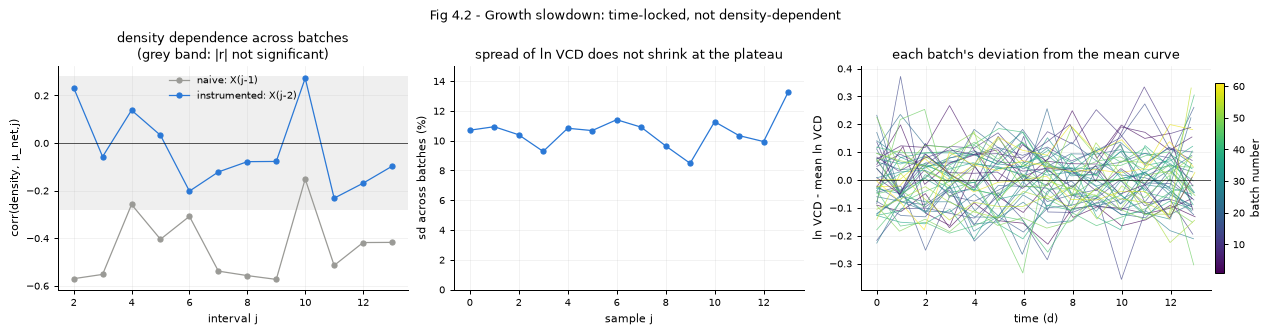

In [19]:
Xw = meas.pivot(index="batch_id", columns="j", values="vcd")
Sw = meas.pivot(index="batch_id", columns="j", values="substrate")
Pw = meas.pivot(index="batch_id", columns="j", values="byproduct")
MU = I.pivot(index="batch_id", columns="j", values="mu_net")
rows = []
for j in range(2, 14):
    x, z = np.log(Xw[j - 1]), np.log(Xw[j - 2])
    rows.append(dict(j=j,
                     r_naive=stats.pearsonr(x, MU[j])[0], p_naive=stats.pearsonr(x, MU[j])[1],
                     r_instrumented=stats.pearsonr(z, MU[j])[0], p_instrumented=stats.pearsonr(z, MU[j])[1],
                     slope_naive=np.cov(MU[j], x)[0, 1] / np.var(x, ddof=1),
                     slope_IV=np.cov(MU[j], z)[0, 1] / np.cov(x, z)[0, 1],
                     r_S=stats.pearsonr(Sw[j - 2], MU[j])[0], r_P=stats.pearsonr(Pw[j - 2], MU[j])[0]))
DD = pd.DataFrame(rows).set_index("j")
display(DD.round(3))

# Pooled instrumented slope over the deceleration intervals 3-9 (per-j demeaned), with a batch bootstrap
def pooled_iv(batches):
    num = den = 0.0
    for j in range(3, 10):
        mu_ = MU.loc[batches, j]; x = np.log(Xw.loc[batches, j - 1]); z = np.log(Xw.loc[batches, j - 2])
        num += np.sum((mu_ - mu_.mean()) * (z - z.mean())); den += np.sum((x - x.mean()) * (z - z.mean()))
    return num / den


rng = np.random.default_rng(0)
boot = [pooled_iv(list(rng.choice(TRAIN, len(TRAIN)))) for _ in range(500)]
iv_hat = pooled_iv(TRAIN)
# logistic benchmark: mu = mu_max (1 - X/Xmax) -> d mu / d lnX = -mu_max X/Xmax, averaged over intervals 3-9
xm = Xw[[*range(2, 9)]].mean().mean() / Xw.max(axis=1).mean()
logistic_slope = -G.mu_max_0_3.mean() * xm
print(f"pooled instrumented slope d mu / d lnX (intervals 3-9) = {iv_hat:.3f}  "
      f"(95% bootstrap CI {np.percentile(boot, 2.5):.3f} .. {np.percentile(boot, 97.5):.3f}); "
      f"a common carrying capacity (logistic) would give about {logistic_slope:.2f}")

# Convergence test: with a common carrying capacity, batches converge at the plateau (spread of ln VCD shrinks)
L = np.log(Xw)
spread = pd.DataFrame({"sd of ln VCD across batches (%)": 100 * L.std(),
                       "corr with own deviation at j=0": [(L[j] - L[j].mean()).corr(L[0] - L[0].mean()) for j in L.columns]})
display(spread.T.round(2))

fig, axs = plt.subplots(1, 3, figsize=(14, 3.6), constrained_layout=True)
axs[0].plot(DD.index, DD.r_naive, "o-", color=C_GREY, ms=4, label="naive: X(j-1)")
axs[0].plot(DD.index, DD.r_instrumented, "o-", color=C_TRAIN, ms=4, label="instrumented: X(j-2)")
axs[0].axhline(0, color="k", lw=0.5)
axs[0].axhspan(-0.28, 0.28, color=C_GREY, alpha=0.15, lw=0)
axs[0].set(xlabel="interval j", ylabel="corr(density, μ_net,j)", title="density dependence across batches\n(grey band: |r| not significant)")
axs[0].legend()
axs[1].plot(spread.index, spread.iloc[:, 0], "o-", color=C_TRAIN, ms=4)
axs[1].set(xlabel="sample j", ylabel="sd across batches (%)", ylim=(0, 15), title="spread of ln VCD does not shrink at the plateau")
for b, g in meas.groupby("batch_id"):
    axs[2].plot(g.elapsed_time, np.log(g.vcd) - L.mean().values[: len(g)], color=bcol(b), lw=0.6, alpha=0.7)
axs[2].axhline(0, color="k", lw=0.5)
axs[2].set(xlabel="time (d)", ylabel="ln VCD - mean ln VCD", title="each batch's deviation from the mean curve")
batch_colorbar(fig, axs[2])
fig.suptitle("Fig 4.2 - Growth slowdown: time-locked, not density-dependent", fontsize=10)
save(fig, "q4_density_dependence")
plt.show()

**Findings (4).** No lag beyond the first day (μ = 0.70 d⁻¹ in interval 1 vs 0.83 in interval 2, p = 0.002).
Exponential phase days 0-3: **μ_max = 0.73 ± 0.03 d⁻¹** (doubling 22.9 h, ln N linear, R² = 0.993). Deceleration
from day 2-3 (0.63, 0.60, 0.42, 0.23, 0.17), stationary at 7.7 ± 0.8 d, net decline of the viable amount from
day ≈ 10 (−0.03 to −0.05 d⁻¹). Peak VCD 31.7 ± 3.0 at 7.7 d; peak viable *amount* 2 days later (dilution).
The naive density dependence (r ≈ −0.5) is a noise artefact; instrumented it vanishes (pooled slope −0.10, CI
−0.23 .. 0.01, vs −0.46 for a logistic carrying capacity) and the cross-batch spread of ln VCD stays ≈ 10 % up to
the plateau. **The growth-rate curve μ(t) is time-locked and common to all batches**; a batch's VCD level is set by
where it started.

## 5. Death & viability

*Mechanisms tested:* first-order death dX_d/dt = k_d·X_v (Xing 2010; Kyriakopoulos 2018) with k_d either constant,
rising with culture age, or triggered by substrate starvation / byproduct toxicity (death terms in K_D/(K_D+S) or
P/(K_DP+P), as in the reference paper Chiu & Du 2025, eq. 19); and **lysis** of dead cells (Kroll 2017), which
would make the total cell amount decrease.

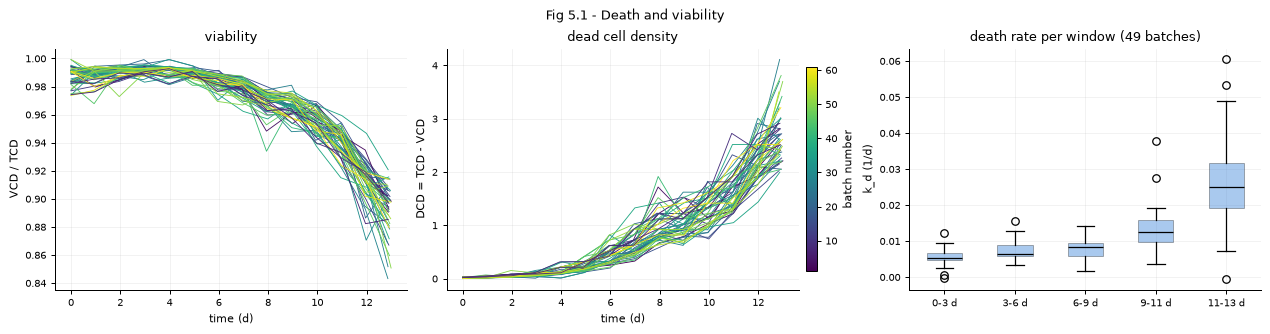

,0-3 d,3-6 d,6-9 d,9-11 d,11-13 d
mean,0.0055,0.0075,0.0080,0.0133,0.0267
50%,0.0053,0.0065,0.0083,0.0126,0.0251
std,0.0021,0.0026,0.0027,0.0055,0.0109


In [20]:
fig, axs = plt.subplots(1, 3, figsize=(14, 3.6), constrained_layout=True)
for b, g in meas.groupby("batch_id"):
    axs[0].plot(g.elapsed_time, g.viability, color=bcol(b), lw=0.7)
    axs[1].plot(g.elapsed_time, g.dcd, color=bcol(b), lw=0.7)
axs[0].set(xlabel="time (d)", ylabel="VCD / TCD", title="viability")
axs[1].set(xlabel="time (d)", ylabel="DCD = TCD - VCD", title="dead cell density")
# k_d over windows (pooling intervals reduces the noise of DCD differences)
WINDOWS = {"0-3 d": range(1, 4), "3-6 d": range(4, 7), "6-9 d": range(7, 10), "9-11 d": range(10, 12),
           "11-13 d": range(12, 14)}


def window_rates(df):
    out = {}
    for name, js in WINDOWS.items():
        g = df[df.j.isin(js)]
        dead = (g.D1 * g.V1 - g.D0 * g.V0 + 0.5 * (g.D0 + g.D1) * g.wd).sum()
        out[name] = dead / g.IVC.sum()
    return pd.Series(out)


KD = I.groupby("batch_id").apply(window_rates)
bp = axs[2].boxplot([KD[c] for c in KD.columns], tick_labels=list(KD.columns), widths=0.5, patch_artist=True,
                    medianprops=dict(color="k"), boxprops=dict(facecolor=C_TRAIN, alpha=0.4, lw=0.6))
axs[2].set(ylabel="k_d (1/d)", title="death rate per window (49 batches)")
batch_colorbar(fig, axs[:2])
fig.suptitle("Fig 5.1 - Death and viability", fontsize=10)
save(fig, "q5_death")
plt.show()
display(KD.describe().loc[["mean", "50%", "std"]].round(4))

In [21]:
# Lysis check: the total cell amount (TCD x V) cannot decrease without lysis (sampling withdrawal is added back).
I["T_rel_change"] = I.dT_amt / (0.5 * (I.T0 * I.V0 + I.T1 * I.V1) * I.dt)
late_T = I[I.j >= 11].groupby("batch_id").T_rel_change.mean()
print("relative change of total cell amount per day, intervals 11-13: median "
      f"{late_T.median():.4f}, share of batches < 0: {(late_T < 0).mean():.2f}, "
      f"t-test vs 0: p = {stats.ttest_1samp(late_T, 0).pvalue:.2g}")
whole = (meas[meas.j == 13].set_index("batch_id").eval("tcd * volume") /
         meas[meas.j == 9].set_index("batch_id").eval("tcd * volume"))
print(f"total cell amount day 13 / day 9: median {whole.median():.3f} (IQR {whole.quantile(.25):.3f}-{whole.quantile(.75):.3f})")

relative change of total cell amount per day, intervals 11-13: median -0.0122, share of batches < 0: 0.61, t-test vs 0: p = 0.23
total cell amount day 13 / day 9: median 0.972 (IQR 0.892-1.056)


,rho,p
S at sample 11 (minimum),0.034,0.817
S min over run,0.028,0.846
P at sample 11,0.002,0.991
P max,0.244,0.091
VCD at sample 11,-0.308,0.032
peak VCD,0.009,0.952
IVCD up to sample 11,-0.049,0.739
k_d 9-11 d,-0.212,0.144


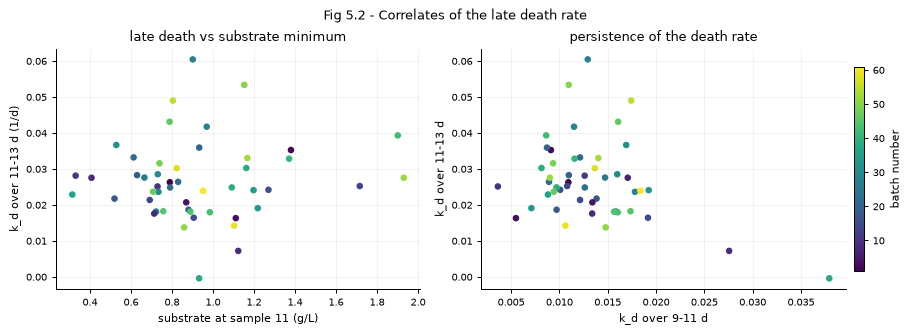

In [22]:
# What correlates with late death? Cross-batch correlations of k_d (11-13 d) with the state before it
end_state = pd.DataFrame({
    "S at sample 11 (minimum)": Sw[11], "S min over run": Sw.min(axis=1), "P at sample 11": Pw[11],
    "P max": Pw.max(axis=1), "VCD at sample 11": Xw[11], "peak VCD": Xw.max(axis=1),
    "IVCD up to sample 11": I[I.j <= 11].groupby("batch_id").IVCD.sum(),
    "k_d 9-11 d": KD["9-11 d"],
})
corr_kd = pd.DataFrame({c: corr_aligned(end_state[c], KD["11-13 d"], "spearman") for c in end_state},
                       index=["rho", "p"]).T
display(corr_kd.round(3))
fig, axs = plt.subplots(1, 2, figsize=(10, 3.6), constrained_layout=True)
axs[0].scatter(end_state["S at sample 11 (minimum)"], KD["11-13 d"], c=[bcol(b) for b in KD.index], s=18)
axs[0].set(xlabel="substrate at sample 11 (g/L)", ylabel="k_d over 11-13 d (1/d)", title="late death vs substrate minimum")
axs[1].scatter(KD["9-11 d"], KD["11-13 d"], c=[bcol(b) for b in KD.index], s=18)
axs[1].set(xlabel="k_d over 9-11 d", ylabel="k_d over 11-13 d", title="persistence of the death rate")
batch_colorbar(fig, axs)
fig.suptitle("Fig 5.2 - Correlates of the late death rate", fontsize=10)
save(fig, "q5_death_correlates")
plt.show()

**Findings (5).** k_d rises with culture age: 0.0055 (0-3 d), 0.0075, 0.008, 0.013, **0.027 d⁻¹ (11-13 d)**, i.e.
roughly doubling every 2.5-3 d after day 6; viability 0.99 → 0.89. Late death is not related to the substrate
minimum (ρ = 0.03), the byproduct (0.00), the IVCD (−0.05) or the earlier death rate, and has no persistent batch
component (ICC 0) → **age-driven, batch-independent death**. The total cell amount is flat after day 9
(ratio 0.97, n.s.): **no detectable lysis**, dead cells accumulate.

## 6. IVCD, specific rates and yields

*Mechanisms tested:* constant specific rates (cumulative amount linear in IVC), the **Pirt** maintenance model
q_S = μ/Y_X/S + m_S, **Luedeking-Piret** for the byproduct q_P = α·μ + β, glucose → lactate **overflow** and the
**lactate shift** to net consumption (Mulukutla 2012; Qin 2026), and Monod dependence of q_S on S.

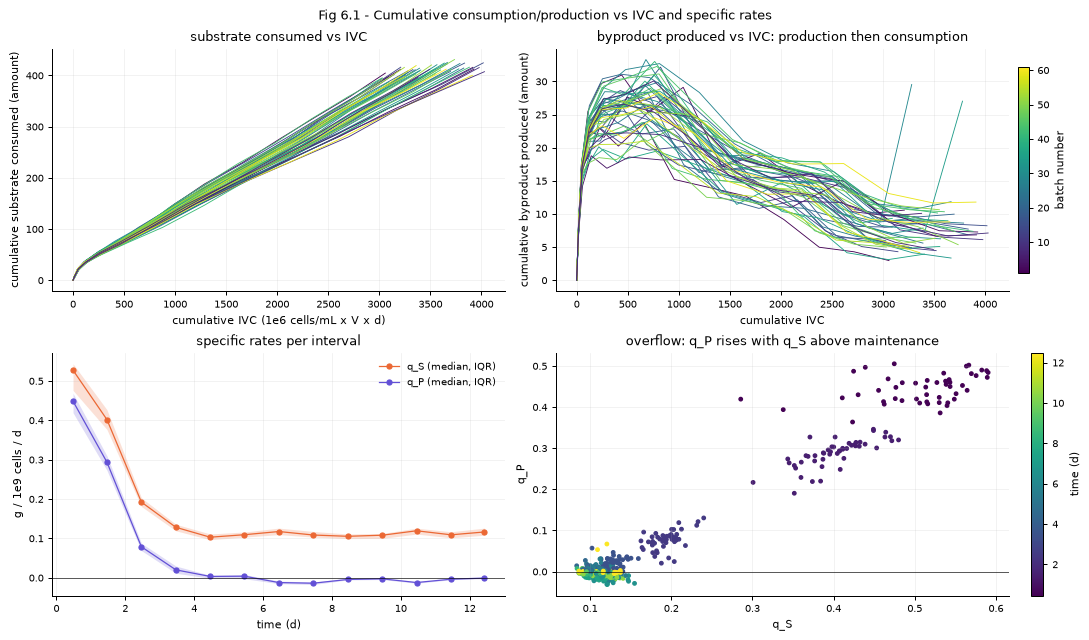

j          1      2      3      4      5      6      7      8      9      10     11     12     13
qS 25%  0.476  0.377  0.181  0.119  0.097  0.103  0.110  0.103  0.099  0.100  0.111  0.101  0.108
   50%  0.527  0.402  0.192  0.128  0.103  0.109  0.117  0.108  0.105  0.108  0.119  0.109  0.116
   75%  0.544  0.427  0.203  0.136  0.111  0.116  0.126  0.118  0.111  0.113  0.126  0.117  0.126
qP 25%  0.419  0.273  0.069  0.011 -0.001 -0.003 -0.015 -0.017 -0.005 -0.005 -0.014 -0.005 -0.002
   50%  0.449  0.294  0.079  0.020  0.003  0.004 -0.012 -0.014 -0.004 -0.003 -0.012 -0.004 -0.001
   75%  0.469  0.310  0.088  0.030  0.006  0.008 -0.008 -0.011 -0.002 -0.001 -0.011 -0.003  0.001

In [23]:
I["S_cons"] = CB * I.B + CF * I.F - I.S_net
I["qS"] = I.S_cons / I.IVC        # g / (1e9 cells) / d  (= ng/cell/d with the assumed units)
I["qP"] = I.P_prod / I.IVC
I = I.sort_values(["batch_id", "j"])
for c in ["IVC", "IVCD", "S_cons", "P_prod"]:
    I[f"cum_{c}"] = I.groupby("batch_id")[c].cumsum()

fig, axs = plt.subplots(2, 2, figsize=(12, 7), constrained_layout=True)
for b, g in I.groupby("batch_id"):
    x = np.r_[0, g.cum_IVC]
    axs[0, 0].plot(x, np.r_[0, g.cum_S_cons], color=bcol(b), lw=0.7)
    axs[0, 1].plot(x, np.r_[0, g.cum_P_prod], color=bcol(b), lw=0.7)
axs[0, 0].set(xlabel="cumulative IVC (1e6 cells/mL x V x d)", ylabel="cumulative substrate consumed (amount)",
              title="substrate consumed vs IVC")
axs[0, 1].set(xlabel="cumulative IVC", ylabel="cumulative byproduct produced (amount)",
              title="byproduct produced vs IVC: production then consumption")
qq = I.groupby("j")[["tm", "qS", "qP", "mu"]].median()
for col, c, lab in [("qS", C_TEST, "q_S"), ("qP", C_4, "q_P")]:
    q25, q75 = I.groupby("j")[col].quantile(0.25), I.groupby("j")[col].quantile(0.75)
    axs[1, 0].fill_between(qq.tm, q25, q75, color=c, alpha=0.2, lw=0)
    axs[1, 0].plot(qq.tm, qq[col], "o-", color=c, ms=4, label=f"{lab} (median, IQR)")
axs[1, 0].axhline(0, color="k", lw=0.5)
axs[1, 0].set(xlabel="time (d)", ylabel="g / 1e9 cells / d", title="specific rates per interval")
axs[1, 0].legend()
sc = axs[1, 1].scatter(I.qS, I.qP, c=I.tm, cmap="viridis", s=8)
fig.colorbar(sc, ax=axs[1, 1], label="time (d)")
axs[1, 1].axhline(0, color="k", lw=0.5)
axs[1, 1].set(xlabel="q_S", ylabel="q_P", title="overflow: q_P rises with q_S above maintenance")
batch_colorbar(fig, axs[0, :])
fig.suptitle("Fig 6.1 - Cumulative consumption/production vs IVC and specific rates", fontsize=10)
save(fig, "q6_yields")
plt.show()
display(I.groupby("j")[["qS", "qP"]].describe().loc[:, (slice(None), ["25%", "50%", "75%"])].T.round(3))

In [24]:
# Are the specific rates batch-dependent? Share of within-interval variance due to a persistent batch effect
# (one-way ANOVA of per-interval-demeaned rates over the stable window j = 5..13)
def batch_share(col, js):
    g = I[I.j.isin(js)].copy()
    g["r"] = g[col] - g.groupby("j")[col].transform("mean")
    groups = [x.r.values for _, x in g.groupby("batch_id")]
    F_, p_ = stats.f_oneway(*groups)
    k = len(js)
    ms_b = np.var([x.mean() for x in groups], ddof=1) * k
    ms_w = np.mean([np.var(x, ddof=1) for x in groups])
    icc = max(0, (ms_b - ms_w) / (ms_b + (k - 1) * ms_w))
    return dict(F=F_, p=p_, ICC=icc)


display(pd.DataFrame({"q_S (j 5-13)": batch_share("qS", range(5, 14)), "q_P (j 5-13)": batch_share("qP", range(5, 14)),
                      "q_P (j 1-3)": batch_share("qP", range(1, 4)), "mu_net (j 3-9)": batch_share("mu_net", range(3, 10)),
                      "k_d (j 8-13)": batch_share("kd", range(8, 14))}).T.round(3))

# Do the AMOUNTS consumed/produced scale with the number of cells across batches? Elasticity of the batch total over
# a window to the batch IVC over the same window (1 = per-cell rate identical in all batches, 0 = amount independent
# of the cells). IVC carries the ~7 % VCD noise, so the instrumented version uses the IVC of the *other* window.
def window_sum(col, js):
    return I[I.j.isin(js)].groupby("batch_id")[col].sum()


rows = []
for name, js, other in [("exponential j1-3", range(1, 4), range(5, 10)), ("late j5-13", range(5, 14), range(1, 4))]:
    ivc, ivc_other = np.log(window_sum("IVC", js)), np.log(window_sum("IVC", other))
    for col in ["S_cons", "P_prod"]:
        y = window_sum(col, js)
        if (y <= 0).any():
            continue
        y = np.log(y)
        ols_ = sm.OLS(y, sm.add_constant(ivc)).fit()
        iv_ = np.cov(y, ivc_other)[0, 1] / np.cov(ivc, ivc_other)[0, 1]
        rows.append(dict(window=name, amount=col, elasticity_OLS=ols_.params.iloc[1], elasticity_IV=iv_,
                         r=np.corrcoef(y, ivc)[0, 1]))
display(pd.DataFrame(rows).round(2))

# Yields and Luedeking-Piret / Pirt fits (simple physical fits on interval rates)
early = I[I.j <= 3]
Y_PS = early.P_prod.sum() / early.S_cons.sum()
Y_XS = (early.growth.sum()) / early.S_cons.sum()
print(f"exponential phase (j 1-3): Y_P/S = {Y_PS:.2f} g/g  (= {Y_PS * 180 / 90:.2f} mol lactate / mol glucose if "
      f"S = glucose, P = lactate; max 2), Y_X/S = {Y_XS:.1f} 1e6 cells/mL·V per g/L·V  (= {Y_XS:.1f}e9 cells/g)")
lp_all = sm.OLS(I.qP, sm.add_constant(I.mu)).fit()
lp_pre = sm.OLS(I[I.tm < 4.5].qP, sm.add_constant(I[I.tm < 4.5].mu)).fit()
lp_post = sm.OLS(I[I.tm >= 4.5].qP, sm.add_constant(I[I.tm >= 4.5].mu)).fit()
pirt = sm.OLS(I[I.j >= 4].qS, sm.add_constant(I[I.j >= 4].mu)).fit()
fits = pd.DataFrame({
    "Luedeking-Piret qP = a*mu + b (all)": [lp_all.params["mu"], lp_all.params["const"], lp_all.rsquared],
    "LP before 4.5 d": [lp_pre.params["mu"], lp_pre.params["const"], lp_pre.rsquared],
    "LP after 4.5 d": [lp_post.params["mu"], lp_post.params["const"], lp_post.rsquared],
    "Pirt qS = mu/Y + m (j >= 4)": [pirt.params["mu"], pirt.params["const"], pirt.rsquared],
}, index=["slope (a or 1/Y)", "intercept (b or m)", "R2"]).T
display(fits.round(4))

,F,p,ICC
q_S (j 5-13),9.782,0.000,0.494
q_P (j 5-13),0.505,0.998,0.000
q_P (j 1-3),2.604,0.000,0.348
mu_net (j 3-9),0.136,1.000,0.000
k_d (j 8-13),0.365,1.000,0.000


,window,amount,elasticity_OLS,elasticity_IV,r
0,exponential j1-3,S_cons,0.32,0.49,0.56
1,exponential j1-3,P_prod,0.19,0.39,0.15
2,late j5-13,S_cons,0.15,0.18,0.54


exponential phase (j 1-3): Y_P/S = 0.63 g/g  (= 1.26 mol lactate / mol glucose if S = glucose, P = lactate; max 2), Y_X/S = 2.4 1e6 cells/mL·V per g/L·V  (= 2.4e9 cells/g)


,slope (a or 1/Y),intercept (b or m),R2
Luedeking-Piret qP = a*mu + b (all),0.2976,-0.0245,0.4795
LP before 4.5 d,0.6183,-0.2295,0.3444
LP after 4.5 d,0.0079,-0.0059,0.0149
Pirt qS = mu/Y + m (j >= 4),0.0085,0.1114,0.0213


,j_peak_P_amount,t_shift,P_conc_max,t_P_conc_max,P_end,consumed_after_peak (amount),qS_at_shift,S_at_shift,mu_at_shift
mean,5.510,5.470,2.548,4.479,0.580,19.207,0.110,2.768,0.359
std,0.767,0.766,0.263,0.817,0.282,4.382,0.013,0.507,0.158
min,3.000,2.974,1.931,2.967,0.280,1.511,0.083,1.699,0.108
50%,6.000,5.944,2.592,3.987,0.531,20.466,0.109,2.850,0.328
max,7.000,6.943,3.030,6.027,1.859,23.939,0.165,3.556,0.794


batches that never switch to net consumption: 0
share of batches with net byproduct production over intervals 12-13: 0.08


S_bin,"(0.0, 0.8]","(0.8, 1.2]","(1.2, 1.6]","(1.6, 2.0]","(2.0, 2.5]","(2.5, 5.0]"
count,5.000,52.000,54.000,33.000,112.000,136.000
median,0.111,0.113,0.117,0.114,0.109,0.110
mean,0.111,0.111,0.117,0.115,0.109,0.112


interval 12 consumption vs substrate at sample 11: rho = -0.04 (p = 0.79)


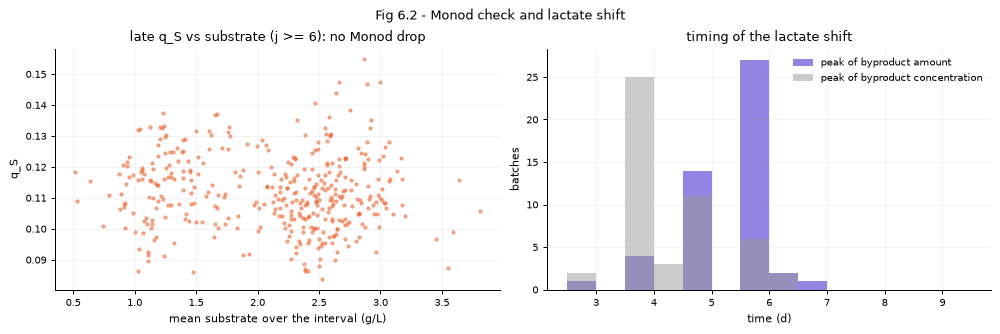

In [25]:
# Lactate shift: when does each batch switch from net production to net consumption?
cumP = I.pivot(index="batch_id", columns="j", values="cum_P_prod")
tm_w = I.pivot(index="batch_id", columns="j", values="t1")
j_shift = cumP.idxmax(axis=1)
shift = pd.DataFrame({"j_peak_P_amount": j_shift, "t_shift": [tm_w.loc[b, j] for b, j in j_shift.items()],
                      "P_conc_max": Pw.max(axis=1), "t_P_conc_max": [meas[(meas.batch_id == b)].set_index("j")
                                                                      .elapsed_time[Pw.loc[b].idxmax()] for b in Pw.index],
                      "P_end": Pw[13], "consumed_after_peak (amount)": cumP.max(axis=1) - cumP[13]})
shift["qS_at_shift"] = [I[(I.batch_id == b) & (I.j == j)].qS.iloc[0] for b, j in j_shift.items()]
shift["S_at_shift"] = [Sw.loc[b, j] for b, j in j_shift.items()]
shift["mu_at_shift"] = [I[(I.batch_id == b) & (I.j == j)].mu.iloc[0] for b, j in j_shift.items()]
display(shift.describe().loc[["mean", "std", "min", "50%", "max"]].round(3))
print("batches that never switch to net consumption:", (shift["consumed_after_peak (amount)"] <= 0).sum())
# Re-accumulation at the end? (lactate production again in the last intervals)
print("share of batches with net byproduct production over intervals 12-13:",
      round((I[I.j >= 12].groupby("batch_id").P_prod.sum() > 0).mean(), 2))

# Monod check: does the specific consumption drop at low substrate? (late intervals, S from 0.3 to 3 g/L)
late_q = I[I.j >= 6].copy()
late_q["S_mean"] = 0.5 * (late_q.S0 + late_q.S1)
late_q["S_bin"] = pd.cut(late_q.S_mean, [0, 0.8, 1.2, 1.6, 2.0, 2.5, 5])
display(late_q.groupby("S_bin", observed=True).qS.agg(["count", "median", "mean"]).round(3).T)
r12 = stats.spearmanr(Sw[11], I[I.j == 12].set_index("batch_id").qS.loc[Sw.index])
print(f"interval 12 consumption vs substrate at sample 11: rho = {r12[0]:.2f} (p = {r12[1]:.2g})")

fig, axs = plt.subplots(1, 2, figsize=(11, 3.6), constrained_layout=True)
axs[0].scatter(late_q.S_mean, late_q.qS, s=6, color=C_TEST, alpha=0.5)
axs[0].set(xlabel="mean substrate over the interval (g/L)", ylabel="q_S", title="late q_S vs substrate (j >= 6): no Monod drop")
axs[1].hist(shift.t_shift, bins=np.arange(2.5, 9.6, 0.5), color=C_4, alpha=0.7, label="peak of byproduct amount")
axs[1].hist(shift.t_P_conc_max, bins=np.arange(2.5, 9.6, 0.5), color=C_GREY, alpha=0.5, label="peak of byproduct concentration")
axs[1].set(xlabel="time (d)", ylabel="batches", title="timing of the lactate shift")
axs[1].legend()
fig.suptitle("Fig 6.2 - Monod check and lactate shift", fontsize=10)
save(fig, "q6_monod_shift")
plt.show()

**Findings (6).** q_S = 0.53 → 0.40 → 0.19 → 0.13 g/10⁹ cells/d over days 0-4, then **constant ≈ 0.11** (zero-order,
≈ 0.6 pmol/cell/d if glucose): no growth-associated term (Pirt slope ≈ 0) and **no Monod drop down to S ≈ 0.3-0.8 g/L**.
Byproduct: q_P = 0.45 → 0.29 → 0.08 → 0 at day 5, then **net consumption** (−0.012 to −0.014 on days 6-8), ≈ 0 after.
Best simple law: **overflow** q_S = m + b·q_P⁺ with m = 0.11, b = 0.86 g/g (Luedeking-Piret fits poorly: R² 0.48,
0.01 after the shift). Early yields: Y_P/S = 0.63 g/g (1.26 mol/mol), Y_X/S ≈ 2.4·10⁹ cells/g.
**Lactate shift** in all 49 batches at 5.5 ± 0.8 d (amount; concentration peak 4.5 d), exactly when q_S has fallen
to the maintenance level (0.110 ± 0.013) while S is still 2.8 g/L → low glycolytic flux (Mulukutla 2012), not
glucose depletion. Across batches the consumed/produced amounts scale weakly with the measured cells (elasticity
0.3-0.5 early, ≈ 0.15 late), so late q_S looks batch-dependent (ICC 0.49) mainly because IVC differs.

## 7. What stops growth?

Hypotheses tested at the end of exponential growth (time t½ where μ_net falls to half of μ_max, per batch):
**H1** substrate limitation (Monod), **H2** byproduct (lactate) inhibition (Ozturk 1992: μ halved at ~55 mM),
**H3** depletion of a nutrient supplied by Feed B/C/D (amino acids: Duarte 2014, Ghaffari 2020),
**H4** density limitation / carrying capacity (logistic, O₂/CO₂ transfer), **H5** a time-locked driver common to all
batches (programmed shift, osmolality/CO₂ from the near-identical feeds and base, cell-cycle arrest - Pan 2019),
**H6** acid stress (pH at its lower limit when base is being added).

Threshold test: if growth stops when a variable reaches a critical value, that variable should be **less variable
across batches at t½ than at a fixed time** (ratio of CVs < 1).

In [26]:
def interp_at(b, var, t):
    g = meas[meas.batch_id == b].sort_values("elapsed_time")
    return np.interp(t, g.elapsed_time, g[var])


meas = meas.sort_values(["batch_id", "j"])
cum_feed = {}
for b in TRAIN:
    fb = FE[FE.batch_id == b]
    cum_feed[b] = fb
t_half = G.t_half_mu
t_fix = t_half.median()
rows = []
for b in TRAIN:
    for when, t in [("t_half", t_half[b]), ("fixed", t_fix)]:
        fb = cum_feed[b]
        gi = I[I.batch_id == b]
        rows.append(dict(batch_id=b, when=when, t=t,
                         S=interp_at(b, "substrate", t), P=interp_at(b, "byproduct", t), VCD=interp_at(b, "vcd", t),
                         viability=interp_at(b, "viability", t), V=interp_at(b, "volume", t),
                         cum_IVCD=np.interp(t, np.r_[0, gi.t1], np.r_[0, gi.cum_IVCD]),
                         cum_B=fb[(fb.feed == "feed_b") & (fb.t <= t)].amount.sum(),
                         n_C_small=((fb.feed == "feed_c") & (fb.amount < 0.0013) & (fb.t <= t)).sum(),
                         cum_P_prod=np.interp(t, np.r_[0, gi.t1], np.r_[0, gi.cum_P_prod]),
                         base_added=H[(H.batch_id == b)].assign(t1=gi.t1.values).query("t1 <= @t").base_est.sum()))
TH = pd.DataFrame(rows)
num_cols = [c for c in TH.columns if c not in ("batch_id", "when", "t")]
cv = TH.groupby("when")[num_cols].agg(lambda s: s.std() / abs(s.mean())).T
cv["CV ratio (t_half / fixed)"] = cv["t_half"] / cv["fixed"]
display(TH[TH.when == "t_half"].describe().loc[["mean", "std", "min", "max"]].round(3))
display(cv.round(3))
print("corr(t_half, ln VCD0) =", np.round(corr_aligned(t_half, np.log(Xw[0])), 3),
      "| corr(t_half, mu_max) =", np.round(corr_aligned(t_half, G.mu_max_0_3), 3))

# H6: do batches that needed more base (acid stress) in intervals 3-5 grow slower in intervals 4-6?
base35 = H[H.split == "train"].query("j in [3, 4, 5]").groupby("batch_id").base_est.sum()
mu46 = I[I.j.isin([4, 5, 6])].groupby("batch_id").mu_net.mean()
print("corr(base added j3-5, mean mu_net j4-6) =", np.round(stats.pearsonr(base35.loc[mu46.index], mu46), 3))

,t,S,P,VCD,viability,V,cum_IVCD,cum_B,n_C_small,cum_P_prod,base_added
mean,4.707,2.320,2.433,21.283,0.990,11.322,37.873,1.102,2.878,25.210,0.210
std,0.480,0.317,0.299,3.712,0.003,0.209,7.959,0.343,1.201,3.502,0.034
min,2.360,1.442,1.794,7.059,0.983,10.683,8.697,0.190,0.000,17.229,0.041
max,5.710,2.990,2.922,28.018,0.996,11.832,55.887,1.917,6.000,31.092,0.268


when,fixed,t_half,CV ratio (t_half / fixed)
S,0.122,0.137,1.119
P,0.119,0.123,1.035
VCD,0.105,0.174,1.654
viability,0.003,0.003,1.041
V,0.008,0.018,2.262
cum_IVCD,0.087,0.210,2.414
cum_B,0.055,0.311,5.665
n_C_small,0.334,0.417,1.249
cum_P_prod,0.132,0.139,1.054
base_added,0.107,0.162,1.519


corr(t_half, ln VCD0) = [-0.016  0.912] | corr(t_half, mu_max) = [-0.136  0.351]
corr(base added j3-5, mean mu_net j4-6) = [0.033 0.822]


**Findings (7).** At t½ = 4.7 ± 0.5 d: S = 2.32 ± 0.32 g/L (≫ any K_S), P = 2.43 ± 0.30 g/L (≈ 27 mM, half of the
55 mM that halves μ in Ozturk 1992), viability 0.99. No variable is *less* dispersed at t½ than at a fixed time
(all CV ratios ≥ 1) → no threshold. t½ does not depend on the inoculum (r = −0.02) or μ_max.
H1 substrate: rejected. H2 byproduct inhibition: rejected as main driver (μ keeps falling while P falls). H3 nutrient
from B: not supported (denser batches get less B per cell but do not grow slower); D and large-C are fixed in time,
so they cannot be separated from time. H4 density / carrying capacity: rejected. H6 acid stress between batches:
not supported (r = 0.03), although the base phase coincides in time with the onset of deceleration.
**H5 time-locked driver: supported.**

## 8. Batch-to-batch variability

*Mechanism tested:* do batch differences in growth, peak density, timing and byproduct come from the **initial
conditions** (inoculum density, initial substrate/byproduct, volume), from the **feed strategy**, or from a
batch-specific physiology? Simple correlations only (Spearman), no model.

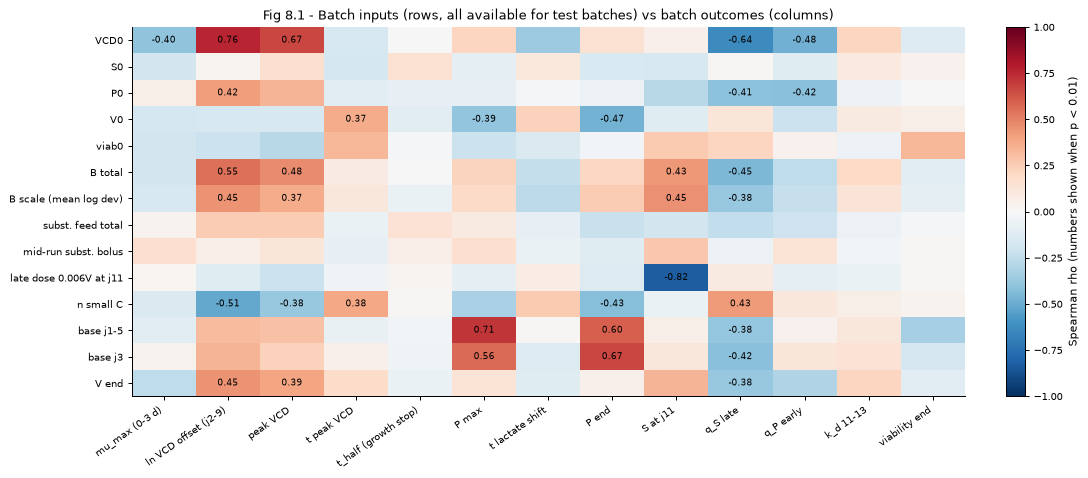

,mu_max (0-3 d),ln VCD offset (j2-9),peak VCD,t peak VCD,t_half (growth stop),P max,t lactate shift,P end,S at j11,q_S late,q_P early,k_d 11-13,viability end
mu_max (0-3 d),1.00,0.06,-0.01,-0.15,-0.14,0.08,0.16,0.21,0.02,-0.11,0.18,-0.25,-0.20
ln VCD offset (j2-9),0.06,1.00,0.84,-0.08,-0.10,0.20,-0.27,0.25,0.20,-0.91,-0.54,0.02,-0.14
peak VCD,-0.01,0.84,1.00,-0.13,-0.07,0.12,-0.16,0.16,0.21,-0.77,-0.52,0.01,-0.12
t peak VCD,-0.15,-0.08,-0.13,1.00,-0.06,-0.19,0.15,-0.09,0.13,0.03,-0.00,0.10,0.18
t_half (growth stop),-0.14,-0.10,-0.07,-0.06,1.00,0.16,-0.16,-0.11,-0.18,0.13,0.11,-0.04,0.17
P max,0.08,0.20,0.12,-0.19,0.16,1.00,0.04,0.66,0.04,-0.18,0.31,0.24,-0.44
t lactate shift,0.16,-0.27,-0.16,0.15,-0.16,0.04,1.00,0.01,-0.20,0.18,0.19,0.14,-0.30
P end,0.21,0.25,0.16,-0.09,-0.11,0.66,0.01,1.00,0.20,-0.37,0.13,-0.06,-0.16
S at j11,0.02,0.20,0.21,0.13,-0.18,0.04,-0.20,0.20,1.00,-0.21,0.08,0.03,0.05
q_S late,-0.11,-0.91,-0.77,0.03,0.13,-0.18,0.18,-0.37,-0.21,1.00,0.46,0.15,0.06


In [27]:
H_tr = H.set_index(["batch_id", "j"]).base_est.unstack()
feat_batch = pd.DataFrame({
    "VCD0": samp[samp.j == 0].set_index("batch_id").vcd, "S0": samp[samp.j == 0].set_index("batch_id").substrate,
    "P0": samp[samp.j == 0].set_index("batch_id").byproduct, "V0": samp[samp.j == 0].set_index("batch_id").volume,
    "viab0": samp[samp.j == 0].set_index("batch_id").viability,
    "B total": FE[FE.feed == "feed_b"].groupby("batch_id").amount.sum(),
    "B scale (mean log dev)": dd.mean(axis=1),
    "subst. feed total": FE[FE.feed == "feed_substrate"].groupby("batch_id").amount.sum(),
    "mid-run subst. bolus": FE[(FE.feed == "feed_substrate") & (FE.j < 11)].groupby("batch_id").size()
    .reindex(samp.batch_id.unique(), fill_value=0).gt(0).astype(int),
    "late dose 0.006V at j11": FE[(FE.feed == "feed_substrate") & (FE.j == 11)].set_index("batch_id").dose_over_V.gt(0.005).astype(int),
    "n small C": FE[(FE.feed == "feed_c") & (FE.amount < 0.0013)].groupby("batch_id").size()
    .reindex(samp.batch_id.unique(), fill_value=0),
    "base j1-5": H_tr[[1, 2, 3, 4, 5]].sum(axis=1),
    "base j3": H_tr[3],
    "V end": samp[samp.j == 13].set_index("batch_id").volume,
})
L = np.log(Xw)
outcomes = pd.DataFrame({
    "mu_max (0-3 d)": G.mu_max_0_3, "ln VCD offset (j2-9)": (L - L.mean())[list(range(2, 10))].mean(axis=1),
    "peak VCD": G.peak_vcd, "t peak VCD": G.t_peak_vcd, "t_half (growth stop)": G.t_half_mu,
    "P max": Pw.max(axis=1), "t lactate shift": shift.t_shift, "P end": Pw[13], "S at j11": Sw[11],
    "q_S late": I[I.j >= 5].groupby("batch_id").qS.mean(), "q_P early": I[I.j <= 3].groupby("batch_id").qP.mean(),
    "k_d 11-13": KD["11-13 d"], "viability end": meas[meas.j == 13].set_index("batch_id").viability,
})
FB = feat_batch.loc[TRAIN]
rho = pd.DataFrame({o: {f: corr_aligned(FB[f], outcomes[o], "spearman")[0] for f in FB} for o in outcomes})
pval = pd.DataFrame({o: {f: corr_aligned(FB[f], outcomes[o], "spearman")[1] for f in FB} for o in outcomes})
fig, ax = plt.subplots(figsize=(12, 5.2), constrained_layout=True)
im = ax.imshow(rho, cmap="RdBu_r", vmin=-1, vmax=1, aspect="auto")
ax.set_xticks(range(rho.shape[1]), rho.columns, rotation=35, ha="right")
ax.set_yticks(range(rho.shape[0]), rho.index)
for i in range(rho.shape[0]):
    for k in range(rho.shape[1]):
        if pval.iloc[i, k] < 0.01:
            ax.text(k, i, f"{rho.iloc[i, k]:.2f}", ha="center", va="center", fontsize=7, color="k")
ax.grid(False)
fig.colorbar(im, ax=ax, label="Spearman rho (numbers shown when p < 0.01)")
ax.set_title("Fig 8.1 - Batch inputs (rows, all available for test batches) vs batch outcomes (columns)")
save(fig, "q8_batch_correlations")
plt.show()

# outcome-outcome correlations (what goes together)
display(outcomes.corr(method="spearman").round(2))

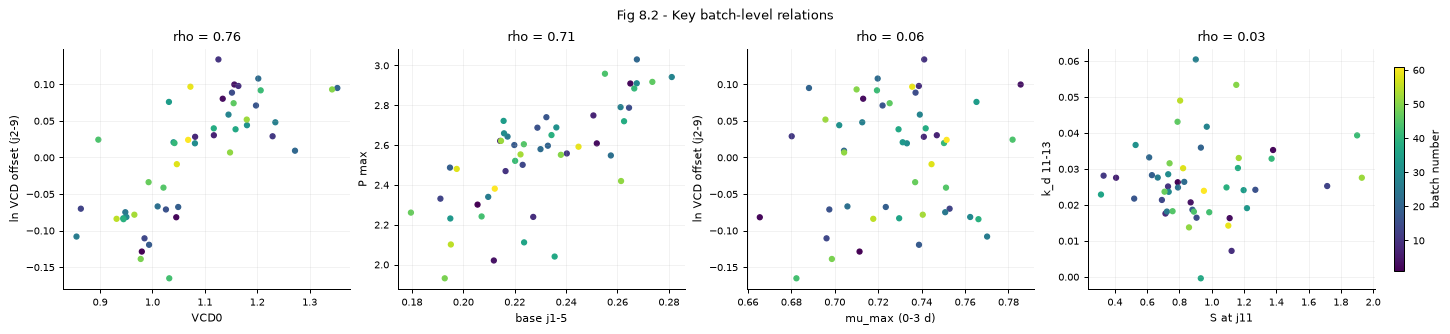

R2(offset ~ ln VCD0) = 0.54
R2(offset ~ mu_max) = 0.02
R2(offset ~ ln VCD0 + mu_max) = 0.77; coef on ln VCD0 = 0.71


In [28]:
fig, axs = plt.subplots(1, 4, figsize=(16, 3.6), constrained_layout=True)
c_ = [bcol(b) for b in TRAIN]
pairs = [("VCD0", "ln VCD offset (j2-9)", feat_batch, outcomes), ("base j1-5", "P max", feat_batch, outcomes),
         ("mu_max (0-3 d)", "ln VCD offset (j2-9)", outcomes, outcomes), ("S at j11", "k_d 11-13", outcomes, outcomes)]
for ax, (xa, ya, dx, dy) in zip(axs, pairs):
    x, y = dx.loc[TRAIN, xa], dy.loc[TRAIN, ya]
    ax.scatter(x, y, c=c_, s=16)
    r = stats.spearmanr(x, y)[0]
    ax.set(xlabel=xa, ylabel=ya, title=f"rho = {r:.2f}")
batch_colorbar(fig, axs)
fig.suptitle("Fig 8.2 - Key batch-level relations", fontsize=10)
save(fig, "q8_key_scatter")
plt.show()

# How much of the persistent VCD offset is the inoculum?
off = outcomes["ln VCD offset (j2-9)"]
for name, x in [("ln VCD0", np.log(feat_batch.loc[TRAIN, "VCD0"])), ("mu_max", outcomes["mu_max (0-3 d)"])]:
    r = corr_aligned(x, off)[0]
    print(f"R2(offset ~ {name}) = {r ** 2:.2f}")
both = sm.OLS(off, sm.add_constant(pd.DataFrame({"lnX0": np.log(feat_batch.loc[TRAIN, "VCD0"]),
                                                  "mu": outcomes["mu_max (0-3 d)"]}))).fit()
print(f"R2(offset ~ ln VCD0 + mu_max) = {both.rsquared:.2f}; coef on ln VCD0 = {both.params['lnX0']:.2f}")

**Findings (8).** The VCD level is set by the **inoculum**: R²(VCD offset ~ ln VCD₀) = 0.54 (0.77 with μ_max),
ρ(VCD₀, peak VCD) = 0.67. The byproduct level is read by the **pH controller**: ρ(base j1-5, P max) = 0.71,
ρ(base, P end) = 0.60. The late substrate is read by the **substrate controller** (0.006·V dose ↔ low S11,
ρ = −0.82) and Feed B scale (0.45). Nothing available explains μ_max, t½, the lactate-shift time, k_d or final
viability → common-mode process behaviour plus noise.

## 9. Test vs training batches

Are the 12 test batches inside the envelope of the 49 training batches for everything we can see about them
(initial state, feeds, volume, hidden base)? Flags: value outside the training [min, max], robust z-score > 3,
and a Mahalanobis distance compared with the leave-one-out distances of the training batches.

In [29]:
feat_test_cols = ["VCD0", "S0", "P0", "V0", "viab0", "B total", "B scale (mean log dev)", "subst. feed total",
                  "mid-run subst. bolus", "late dose 0.006V at j11", "n small C", "base j1-5", "base j3", "V end"]
FT = feat_batch[feat_test_cols].copy()
# per-day Feed B doses and sampling-time jitter
Bd = B.pivot(index="batch_id", columns="j", values="amount").add_prefix("B dose j")
FT = FT.join(Bd)
tr_, te_ = FT.loc[TRAIN], FT.loc[TEST]
med, mad = tr_.median(), 1.4826 * (tr_ - tr_.median()).abs().median()
flags = []
for b in TEST:
    for c in FT.columns:
        v = te_.loc[b, c]
        out_range = (v < tr_[c].min()) or (v > tr_[c].max())
        z = (v - med[c]) / mad[c] if mad[c] > 0 else 0.0
        pct = (tr_[c] < v).mean() * 100
        if out_range or abs(z) > 3:
            flags.append(dict(batch_id=b, feature=c, value=v, train_min=tr_[c].min(), train_max=tr_[c].max(),
                              robust_z=z, percentile=pct))
FL = pd.DataFrame(flags)
print(f"{len(FL)} flags over {len(TEST)} test batches x {FT.shape[1]} features")
display(FL.round(4))
cmp = pd.DataFrame({"train min": tr_.min(), "train median": tr_.median(), "train max": tr_.max(),
                    "test min": te_.min(), "test median": te_.median(), "test max": te_.max()})
display(cmp.round(4))

14 flags over 12 test batches x 26 features


,batch_id,feature,value,train_min,train_max,robust_z,percentile
0,Batch5,P0,0.3022,0.2310,0.3000,2.6891,100.0000
1,Batch5,B dose j12,0.5556,0.4610,0.5525,2.2335,100.0000
2,Batch6,subst. feed total,0.1788,0.1252,0.2098,5.0122,79.5918
3,Batch6,B dose j1,0.0424,0.0425,0.0833,-3.1218,0.0000
4,Batch32,VCD0,1.3631,0.8550,1.3528,2.2927,100.0000
5,Batch32,subst. feed total,0.1292,0.1252,0.2098,-7.7612,4.0816
6,Batch35,subst. feed total,0.1839,0.1252,0.2098,6.3344,83.6735
7,Batch35,B dose j10,0.4305,0.4408,0.5216,-2.6913,0.0000
8,Batch40,P0,0.3023,0.2310,0.3000,2.6969,100.0000
9,Batch48,B dose j10,0.5241,0.4408,0.5216,2.8512,100.0000


,train min,train median,train max,test min,test median,test max
VCD0,0.8550,1.0681,1.3528,0.9348,1.0839,1.3631
S0,4.2189,4.6439,4.9931,4.1630,4.7168,4.9001
P0,0.2310,0.2609,0.3000,0.2429,0.2701,0.3082
V0,10.2982,10.4418,10.6384,10.3107,10.4607,10.5329
viab0,0.9736,0.9898,0.9992,0.9817,0.9848,0.9940
B total,6.1805,6.5495,6.9605,6.3563,6.6493,6.9036
B scale (mean log dev),-0.0819,-0.0034,0.0924,-0.0357,0.0183,0.0515
subst. feed total,0.1252,0.1593,0.2098,0.1292,0.1603,0.1888
mid-run subst. bolus,0.0000,0.0000,1.0000,0.0000,0.0000,1.0000
late dose 0.006V at j11,0.0000,1.0000,1.0000,0.0000,0.0000,1.0000


squared Mahalanobis distance: train LOO median 26.7 | 95th pct 43.8


,test D2,percentile among train LOO
Batch5,18.1,24.5
Batch6,37.5,81.6
Batch12,13.6,14.3
Batch24,10.2,4.1
Batch32,32.0,67.3
Batch35,34.1,77.6
Batch40,42.8,89.8
Batch48,35.0,77.6
Batch54,32.3,69.4
Batch56,11.7,6.1


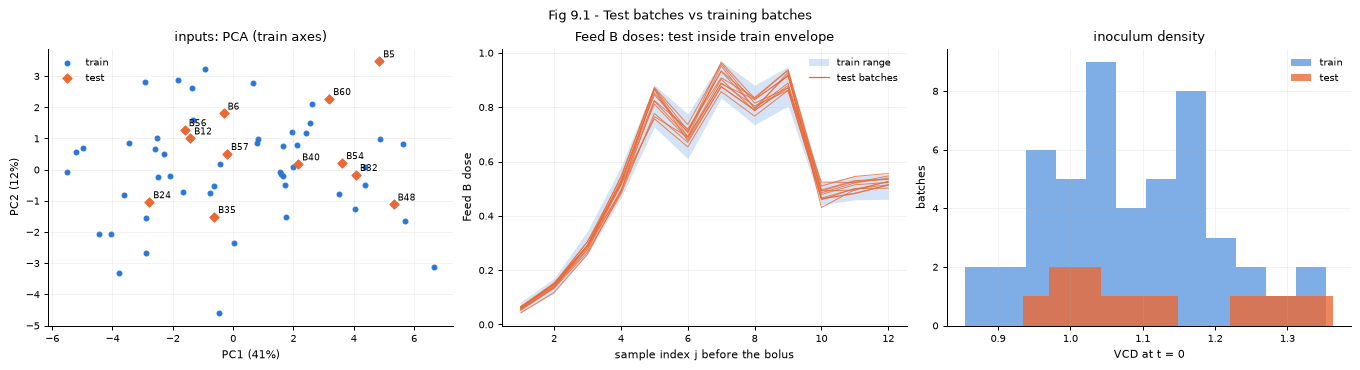

In [30]:
# Multivariate check: standardised features, Mahalanobis distance (Ledoit-Wolf shrinkage) and PCA
from sklearn.covariance import LedoitWolf
from sklearn.decomposition import PCA

cont = [c for c in FT.columns if FT[c].nunique() > 2]
Zt = (FT[cont] - tr_[cont].mean()) / tr_[cont].std()
lw = LedoitWolf().fit(Zt.loc[TRAIN])
d_test = pd.Series(lw.mahalanobis(Zt.loc[TEST]), index=TEST)
d_loo = {}
for b in TRAIN:
    rest = [x for x in TRAIN if x != b]
    d_loo[b] = LedoitWolf().fit(Zt.loc[rest]).mahalanobis(Zt.loc[[b]])[0]
d_loo = pd.Series(d_loo)
print("squared Mahalanobis distance: train LOO median", round(d_loo.median(), 1), "| 95th pct", round(d_loo.quantile(0.95), 1))
display(pd.DataFrame({"test D2": d_test, "percentile among train LOO": [(d_loo < v).mean() * 100 for v in d_test]}).round(1))

pca = PCA(2).fit(Zt.loc[TRAIN])
P_tr, P_te = pca.transform(Zt.loc[TRAIN]), pca.transform(Zt.loc[TEST])
fig, axs = plt.subplots(1, 3, figsize=(15, 4), constrained_layout=True)
axs[0].scatter(P_tr[:, 0], P_tr[:, 1], s=14, color=C_TRAIN, label="train")
axs[0].scatter(P_te[:, 0], P_te[:, 1], s=26, color=C_TEST, marker="D", label="test")
for (x_, y_), b in zip(P_te, TEST):
    axs[0].annotate(b.replace("Batch", "B"), (x_, y_), fontsize=7, xytext=(3, 3), textcoords="offset points")
axs[0].set(xlabel=f"PC1 ({100 * pca.explained_variance_ratio_[0]:.0f}%)",
           ylabel=f"PC2 ({100 * pca.explained_variance_ratio_[1]:.0f}%)", title="inputs: PCA (train axes)")
axs[0].legend()
Bp = B.pivot(index="batch_id", columns="j", values="amount")
axs[1].fill_between(Bp.columns, Bp.loc[TRAIN].min(), Bp.loc[TRAIN].max(), color=C_TRAIN, alpha=0.2, lw=0, label="train range")
for b in TEST:
    axs[1].plot(Bp.columns, Bp.loc[b], color=C_TEST, lw=0.8, alpha=0.8)
axs[1].plot([], [], color=C_TEST, label="test batches")
axs[1].set(xlabel="sample index j before the bolus", ylabel="Feed B dose", title="Feed B doses: test inside train envelope")
axs[1].legend()
axs[2].hist(feat_batch.loc[TRAIN, "VCD0"], bins=12, color=C_TRAIN, alpha=0.6, label="train")
axs[2].hist(feat_batch.loc[TEST, "VCD0"], bins=12, color=C_TEST, alpha=0.8, label="test")
axs[2].set(xlabel="VCD at t = 0", ylabel="batches", title="inoculum density")
axs[2].legend()
fig.suptitle("Fig 9.1 - Test batches vs training batches", fontsize=10)
save(fig, "q9_test_vs_train")
plt.show()

**Findings (9).** No real extrapolation. 14 univariate flags out of 312, all marginal: Batch54 S₀ = 4.16 (train min
4.22) and a mid-run substrate bolus; Batch32 VCD₀ = 1.363 (train max 1.353); Batch5/40/57 P₀ 0.302-0.308 (max 0.300);
a few Feed B doses ≤ 3 % outside the range; "substrate feed total" flags only reflect 2 vs 3 boluses. All Mahalanobis
distances lie inside the training leave-one-out distribution (max percentile 90 %, Batch40). The main
risk is structural: 3 test batches (Batch6, 35, 54) have a mid-run substrate bolus, as only 7/49 training batches do.